# 16_2 · Recalibración G/F con la ponderación histórica de biomasa

El único cambio en el objetivo químico de LAB004–009 es la escala de biomasa viable. Se usa la del ajuste de `pyomo-doe`, \(\sigma_X=\max(0{,}06,0{,}08|X_{\rm obs}|)\) en g/L, en lugar de los 0,50 g/L del 16. Se conservan las iniciales, muestras, temperaturas y pulsos de la recalibración 16. Se reproduce su optimizador de dos arranques del commit `947f97b`, incluidos los parámetros libres, fijos y sus cotas. El análisis se concentra en la química; los parámetros de gas quedan fuera del ajuste.

El 16 con solubilidad variable aporta el vector químico de referencia. El error firmado se define como predicción menos observación. Las comparaciones usan las mismas muestras de biomasa en g/L y excluyen las usadas para inicializar.

In [1]:
from pathlib import Path
from dataclasses import replace
import sys,json
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/wine_fermentation').is_dir())
assert Path(sys.prefix).name.lower()=='fermentation'
sys.path.insert(0,str(ROOT/'src'));sys.dont_write_bytecode=True
from wine_fermentation import model as kin
from wine_fermentation.data import natural_batches
data,training,profiles=natural_batches(ROOT)
# Correcciones de recuento inicial indicadas por el usuario; originales conservados.
INITIAL_VIABLE_MCELLS_ML={'LAB004':10.75,'LAB005':11.25}
initial_biomass_audit=[];corrected_training=[]
for batch in training:
 if batch.batch in INITIAL_VIABLE_MCELLS_ML:
  count=INITIAL_VIABLE_MCELLS_ML[batch.batch];x0=count*.03
  ids=np.flatnonzero(np.isclose(batch.time,0.));assert len(ids)==1
  obs0={k:v.copy() for k,v in batch.observations.items()};obs0['X'][ids[0]]=x0
  initial_biomass_audit.append(dict(LAB=batch.batch,original_g_L=batch.initials['X'],viables_millones_mL=count,corregido_g_L=x0))
  batch=replace(batch,initials={**batch.initials,'X':x0},observations=obs0)
  mask=data.batch.eq(batch.batch)&np.isclose(data.time_h,0.)
  assert mask.sum()==1
  data.loc[mask,'X_viable_kg_m3']=x0;data.loc[mask,'X_viable_mcells_ml']=count
  assert batch.initials['X']==batch.observations['X'][ids[0]]
 corrected_training.append(batch)
training=corrected_training
assert len(initial_biomass_audit)==2
display(pd.DataFrame(initial_biomass_audit))

start=kin.normalize_parameters(json.loads((ROOT/'configs/theta/theta_full.json').read_text()))
config=json.loads((ROOT/'configs/models/without_transporters/calibration.json').read_text())
# Tabla 2 de Zenteno: Kn=0.01 g/L a23C; nuestro Kn0 se referencia a20C.
KN_ZENTENO_G_L=0.01;KN_PAPER_REF_K=296.15;KN_CODE_REF_K=293.15
KN_THERMAL_FACTOR=np.exp(kin.FIXED_CONSTANTS['EaKn']*(KN_PAPER_REF_K-KN_CODE_REF_K)/(KN_CODE_REF_K*kin.FIXED_CONSTANTS['R']*KN_PAPER_REF_K))
start['Kn0']=KN_ZENTENO_G_L/KN_THERMAL_FACTOR
KD0_ZENTENO_H=0.00044
start['Kd0']=KD0_ZENTENO_H
assert np.isclose(start['Kn0']*KN_THERMAL_FACTOR,KN_ZENTENO_G_L,rtol=1e-14)
display(pd.Series(dict(Kn_Zenteno_g_L=KN_ZENTENO_G_L,referencia_paper_C=23,Kn0_codigo_g_L=start['Kn0'],referencia_codigo_C=20),name='Kn fijo y conversión de referencia térmica'))
names=[k for k in config['bounds'] if k not in ['aN','KNa','Kn0','Kd0']]
assert len(names)==8 and 'Kn0' not in names and 'Kd0' not in names
bounds={k:config['bounds'][k] for k in names};lo,hi=np.array(list(bounds.values())).T
fixed={k:v for k,v in start.items() if k not in names}
display(pd.Series(fixed,name='Fijos: theta_full salvo Kn y Kd0 de Zenteno'))
display(pd.DataFrame([dict(parametro=k,inicio=start[k],inicio_factible=np.clip(start[k],lo[i]+1e-10,hi[i]-1e-10),minimo=lo[i],maximo=hi[i]) for i,k in enumerate(names)]))

theta16={'mu0': 0.09403147367985473, 'betaG0': 0.42243676903335664, 'betaF0': 0.6236552480900203, 'Kn0': 0.008257860224319971, 'Kg0': 4.400775419123265, 'Kf0': 19.296083508118652, 'Kig0': 65.01993873457147, 'Kie0': 96.26516563486751, 'Kd0': 0.00044, 'Yxn': 6.456225797038313, 'Yxg': 0.9660935553477866, 'Yxf': 1.1098958529485594, 'Yeg': 0.4684585383875136, 'Yef': 0.5113278649826252, 'm0': 0.0183385793928771}
assert all(theta16[k] == v for k, v in fixed.items())

,LAB,original_g_L,viables_millones_mL,corregido_g_L
0,LAB004,0.3939,10.75,0.3225
1,LAB005,0.4932,11.25,0.3375


Kn_Zenteno_g_L          0.010000
referencia_paper_C     23.000000
Kn0_codigo_g_L          0.008258
referencia_codigo_C    20.000000
Name: Kn fijo y conversión de referencia térmica, dtype: float64

Kn0     0.008258
Kg0     4.400775
Kf0    19.296084
Kd0     0.000440
Yxg     0.966094
Yxf     1.109896
m0      0.018339
Name: Fijos: theta_full salvo Kn y Kd0 de Zenteno, dtype: float64

,parametro,inicio,inicio_factible,minimo,maximo
0,mu0,0.078728,0.078728,0.05,1.0000
1,betaG0,0.428878,0.428878,0.10,10.0000
2,betaF0,3.440399,3.440399,0.10,10.0000
3,Kig0,17.845213,17.845213,5.00,1000.0000
4,Kie0,24.895476,24.895476,5.00,1000.0000
5,Yxn,3.734653,3.734653,1.00,100.0000
6,Yeg,0.250395,0.250395,0.10,0.5114
7,Yef,0.684927,0.511400,0.10,0.5114


## Tratamientos de YAN

Las observaciones de YAN de hasta 20 mg N/L se llevan a cero. Se identifica el agotamiento como la primera observación igual a cero en el pulso o después, y se excluyen muestras estrictamente posteriores a agotamiento + 12 h. En LAB006, la lectura de 27 mg N/L a las 122 h se lleva a cero y el corte es después de las 134 h. Se conserva el YAN inicial medido. Los pulsos son saltos de 80 mg N/L a las horas del 16. Una muestra coincidente con el pulso se evalúa antes de añadir la dosis.

In [2]:
diffs=[]
bylab={b.batch:b for b in training}
for a,b in [('LAB004','LAB005'),('LAB007','LAB008')]:
 aa=pd.Series(bylab[a].observations['X'],index=bylab[a].time);bb=pd.Series(bylab[b].observations['X'],index=bylab[b].time)
 z=pd.concat([aa,bb],axis=1).dropna();diffs.extend((z.iloc[:,0]-z.iloc[:,1]).tolist())
sigma_rep=float(np.sqrt(np.mean(np.square(diffs)))/np.sqrt(2));SIGMA_X=max(.5,3*sigma_rep)
assert len(diffs)>0
print('Pares de réplicas:',len(diffs),'sigma réplica:',sigma_rep,'sigmaX de referencia del 16:',SIGMA_X)
treated=[];audit=[];rules=[]
for b in training:
 obs={k:v.copy() for k,v in b.observations.items()};old=obs['N'].copy()
 obs['N'][np.isfinite(old)&(old<=.020)]=0
 if b.batch=='LAB006':
  ids=np.flatnonzero(np.isclose(b.time,122)&np.isfinite(old));assert len(ids)==1 and np.isclose(old[ids[0]],.027)
  obs['N'][ids]=0;depletion=122.
 else:
  last=max(t for t,d in b.pulses['N']);ids=np.flatnonzero((b.time>=last)&np.isfinite(obs['N'])&(obs['N']==0));assert len(ids)
  depletion=float(b.time[ids[0]])
 obs['N'][b.time>depletion+12]=np.nan
 for i in np.flatnonzero(np.isfinite(old)):
  audit.append(dict(LAB=b.batch,t_h=b.time[i],original_mg=old[i]*1000,usado_mg=obs['N'][i]*1000,estado='Inicial' if b.time[i]==0 else ('Excluido' if not np.isfinite(obs['N'][i]) else ('Transformado' if old[i]!=obs['N'][i] else 'Usado'))))
 assert all(np.array_equal(obs[k],b.observations[k],equal_nan=True) for k in obs if k!='N')
 treated.append(replace(b,observations=obs))
 rules.append(dict(LAB=b.batch,agotamiento_h=depletion,corte_YAN_h=depletion+12,N0_mg=b.initials['N']*1000,pulsos=b.pulses['N'],**{k:int(np.count_nonzero(np.isfinite(obs[k])&(b.time>0))) for k in obs}))
audit=pd.DataFrame(audit);display(pd.DataFrame(rules));display(audit)
def sigma(state, y):
 if state == 'X':
  return np.maximum(.06, .08 * np.abs(y))
 return kin.sigma_for_state(state, y)
def simulate(b,p):
 def rhs(t,y):
  out=np.asarray(kin.rhs(t,y,p,b))
  if y[2]<=0 or y[3]<=0:
   q=kin.kinetic_terms(p,kin.temperature_at(b,t),*y);growth=q['mu']*max(float(y[0]),0)
   out[0]-=growth;out[1]+=growth/p['Yxn'];out[2]+=growth/p['Yxg'];out[3]+=growth/p['Yxf']
  return out
 # Muestra previa al salto si coincide con la nutrición; dosis completa después.
 minimum=np.full(5,np.inf);jumps=[];events={}
 for tp,dose in b.pulses.get('N',()):
  assert tp>float(b.time[0]) and dose>=0,'No se admiten pulsos iniciales extra'
  if tp<=b.time[-1]:events[float(tp)]=events.get(float(tp),0.)+float(dose)
 times=np.asarray(b.time);state=kin.initial_vector(b);records={float(times[0]):state.copy()};now=float(times[0])
 for end in sorted(set([float(times[-1])]+list(events))):
  requested=times[(times>now)&(times<=end)]
  sol=solve_ivp(rhs,(now,end),state,t_eval=np.unique(np.r_[requested,end]),method='LSODA',rtol=2e-6,atol=2e-8,max_step=.5)
  if not sol.success or not np.isfinite(sol.y).all() or np.any(sol.y.min(axis=1)<-np.array([1e-6,1e-6,1e-4,1e-4,1e-6])):raise RuntimeError('Integración química inválida '+b.batch+' '+str(sol.message)+' mínimos='+str(dict(zip(kin.STATE_NAMES,sol.y.min(axis=1)))))
  minimum=np.minimum(minimum,sol.y.min(axis=1))
  records.update({float(t):y.copy() for t,y in zip(sol.t,sol.y.T)});state=sol.y[:,-1].copy();now=end
  if end in events:
   before=state.copy();state[1]+=events[end]
   assert np.isclose(state[1]-before[1],events[end],atol=1e-12) and np.array_equal(state[[0,2,3,4]],before[[0,2,3,4]])
   jumps.append(dict(t=end,dose=events[end],before=before.copy(),after=state.copy()))
 f=pd.DataFrame(np.maximum(np.vstack([records[float(t)] for t in times]),0),index=times,columns=kin.STATE_NAMES);f['GF']=f.G+f.F
 f.attrs['minimum_integrated_states']=dict(zip(kin.STATE_NAMES,minimum.tolist()))
 f.attrs['pulse_jumps']=jumps
 assert np.isclose(sum(j['dose'] for j in jumps),sum(events.values()),atol=1e-12)
 return f

def with_jumps(f):
 extra=[];tt=[]
 for j in f.attrs['pulse_jumps']:
  if j['t'] not in f.index:extra.append(j['before']);tt.append(j['t'])
  extra.append(j['after']);tt.append(j['t'])
 if not extra:return f
 added=pd.DataFrame(extra,index=tt,columns=kin.STATE_NAMES);added['GF']=added.G+added.F
 return pd.concat([f,added]).sort_index(kind='stable')

support=[(b,s,np.isfinite(b.observations[s])&(b.time>0)) for b in treated for s in kin.STATE_NAMES]
NR=sum(m.sum() for b,s,m in support);calls=0;rejected=0

support_counts = {s: sum(int(mask.sum()) for _, state, mask in support if state == s)
                  for s in kin.STATE_NAMES}
assert support_counts == {'X': 64, 'N': 47, 'G': 73, 'F': 73, 'E': 26}
assert len(treated) == 6 and all(len(b.pulses['N']) == 1 and b.pulses['N'][0][1] == .08 for b in treated)
lab006 = next(b for b in treated if b.batch == 'LAB006')
assert lab006.observations['N'][lab006.time == 122].item() == 0.
assert np.isnan(lab006.observations['N'][lab006.time > 134]).all()
print('Observaciones en el objetivo', support_counts)


Pares de réplicas: 23 sigma réplica: 0.1189341469231937 sigmaX de referencia del 16: 0.5
Observaciones en el objetivo {'X': 64, 'N': 47, 'G': 73, 'F': 73, 'E': 26}


,LAB,agotamiento_h,corte_YAN_h,N0_mg,pulsos,X,N,G,F,E
0,LAB004,91.0,103.0,230.76,"((68.5, 0.08),)",10,8,12,12,4
1,LAB005,91.0,103.0,227.30,"((68.5, 0.08),)",10,8,12,12,4
2,LAB006,122.0,134.0,229.12,"((100.0, 0.08),)",12,9,14,14,4
3,LAB007,88.0,100.0,239.04,"((65.5, 0.08),)",11,8,12,12,5
4,LAB008,88.0,100.0,239.22,"((65.5, 0.08),)",11,8,12,12,5
5,LAB009,64.0,76.0,237.40,"((41.84615384615385, 0.08),)",10,6,11,11,4


,LAB,t_h,original_mg,usado_mg,estado
0,LAB004,0.0,230.76,230.76,Inicial
1,LAB004,19.0,182.72,182.72,Usado
2,LAB004,26.0,157.42,157.42,Usado
3,LAB004,43.0,60.16,60.16,Usado
4,LAB004,50.0,19.00,0.00,Transformado
...,...,...,...,...,...
74,LAB009,88.0,17.00,NaN,Excluido
75,LAB009,96.0,19.00,NaN,Excluido
76,LAB009,120.0,5.00,NaN,Excluido
77,LAB009,144.0,25.00,NaN,Excluido


## Ajuste químico en LAB004–009

In [3]:
def residual(logp):
 global calls,rejected
 calls+=1;p={**start,**dict(zip(names,np.exp(logp)))}
 try:pred={b.batch:simulate(b,p) for b in treated}
 except (RuntimeError,ValueError,FloatingPointError):
  rejected+=1;return np.full(NR,1e4)
 e=np.concatenate([(pred[b.batch][s].to_numpy()[m]-b.observations[s][m])/sigma(s,b.observations[s][m]) for b,s,m in support])
 if calls%50==0:print('Evaluaciones',calls,'MSE',float(np.mean(e*e)),'rechazos',rejected,flush=True)
 return e
rng=np.random.default_rng(20261101);x0=np.array([start[k] for k in names]);seeds=[x0,x0*np.exp(rng.normal(0,.2,len(names)))];runs=[];runrows=[]
for j,seed in enumerate(seeds):
 sol=least_squares(residual,np.log(np.clip(seed,lo+1e-10,hi-1e-10)),bounds=(np.log(lo),np.log(hi)),max_nfev=100,diff_step=1e-3,ftol=2e-5,xtol=2e-5,gtol=2e-5)
 runs.append(sol);runrows.append(dict(inicio=j,success=sol.success,nfev=sol.nfev,MSE=float(np.mean(sol.fun**2)),message=sol.message));print(runrows[-1],flush=True)
best=min(runs,key=lambda s:s.fun@s.fun);theta={**start,**dict(zip(names,np.exp(best.x)))}
assert theta['Kd0']==KD0_ZENTENO_H and 'Kd0' not in names
assert theta['Kn0']==start['Kn0'] and np.isclose(theta['Kn0']*KN_THERMAL_FACTOR,.01,rtol=1e-14)
assert theta['Yeg']<=.5114 and theta['Yef']<=.5114 and all(theta[k]==v for k,v in fixed.items())
display(pd.DataFrame(runrows));display(pd.DataFrame([dict(parametro=k,valor=theta[k],minimo=lo[i],maximo=hi[i],cerca_cota=min(abs(np.log(theta[k]/lo[i])),abs(np.log(hi[i]/theta[k])))<.02) for i,k in enumerate(names)]))
print('PARÁMETROS QUÍMICOS COMPLETOS',json.dumps(theta,indent=2));print('Rechazos:',rejected,'Razón singular:',np.linalg.svd(best.jac,compute_uv=False)[-1]/np.linalg.svd(best.jac,compute_uv=False)[0])
traincurves={b.batch:simulate(b,theta) for b in treated}


Evaluaciones 50 MSE 4.771254631260028 rechazos 0
Evaluaciones 100 MSE 4.715812800112503 rechazos 0
{'inicio': 0, 'success': True, 'nfev': 14, 'MSE': 4.715502281177189, 'message': '`ftol` termination condition is satisfied.'}
Evaluaciones 150 MSE 4.879898460948135 rechazos 0
Evaluaciones 200 MSE 4.7213480480199905 rechazos 0
Evaluaciones 250 MSE 4.71554575826321 rechazos 0
{'inicio': 1, 'success': True, 'nfev': 18, 'MSE': 4.715509762215943, 'message': '`ftol` termination condition is satisfied.'}
PARÁMETROS QUÍMICOS COMPLETOS {
  "mu0": 0.08672190419703954,
  "betaG0": 0.4282909568167695,
  "betaF0": 0.5935206388397897,
  "Kn0": 0.008257860224319971,
  "Kg0": 4.400775419123265,
  "Kf0": 19.296083508118652,
  "Kig0": 80.49079852882808,
  "Kie0": 168.1204117857583,
  "Kd0": 0.00044,
  "Yxn": 5.272367998666498,
  "Yxg": 0.9660935553477866,
  "Yxf": 1.1098958529485594,
  "Yeg": 0.45954668102377283,
  "Yef": 0.5105977085906764,
  "m0": 0.0183385793928771
}
Rechazos: 0 Razón singular: 0.01677

,inicio,success,nfev,MSE,message
0,0,True,14,4.715502,`ftol` termination condition is satisfied.
1,1,True,18,4.715510,`ftol` termination condition is satisfied.


,parametro,valor,minimo,maximo,cerca_cota
0,mu0,0.086722,0.05,1.0000,False
1,betaG0,0.428291,0.10,10.0000,False
2,betaF0,0.593521,0.10,10.0000,False
3,Kig0,80.490799,5.00,1000.0000,False
4,Kie0,168.120412,5.00,1000.0000,False
5,Yxn,5.272368,1.00,100.0000,False
6,Yeg,0.459547,0.10,0.5114,False
7,Yef,0.510598,0.10,0.5114,True


## Comparación de parámetros y residuos

Se evalúan ambos vectores con las mismas muestras. Las métricas físicas de biomasa permiten comparar el nivel de sobreestimación independientemente de la escala utilizada por el optimizador. La tabla de MSE por especie presenta ambos vectores bajo cada una de las dos ponderaciones.

In [4]:
parameter_table = pd.DataFrame({"16": theta16, "16_2": theta})
parameter_table["Cambio %"] = 100 * (parameter_table["16_2"] / parameter_table["16"] - 1)
parameter_table["Condición"] = ["Libre" if k in names else "Fijo" for k in parameter_table.index]
display(parameter_table.round(6))
print("Y_X/N [g/g]", {k: float(parameter_table.loc["Yxn", k]) for k in ("16", "16_2", "Cambio %")})

reference_curves = {b.batch: simulate(b, theta16) for b in treated}
predictions = {"16": reference_curves, "16_2": traincurves}
rows = []
for b, state, mask in support:
    hours = b.time[mask]
    observations = b.observations[state][mask]
    pulse = b.pulses["N"][0][0]
    for model, curves in predictions.items():
        values = curves[b.batch][state].to_numpy()[mask]
        errors = values - observations
        for hour, error, scale16, scale_new in zip(
            hours, errors, np.full(len(errors), SIGMA_X) if state == "X" else kin.sigma_for_state(state, observations),
            sigma(state, observations),
        ):
            rows.append({"LAB": b.batch, "Estado": state, "Modelo": model, "Hora": hour,
                         "Periodo": "Antes" if hour <= pulse else "Después", "Error": error,
                         "Error² (peso 16)": (error / scale16)**2,
                         "Error² (peso 16_2)": (error / scale_new)**2})
errors = pd.DataFrame(rows)
assert errors.groupby("Modelo").size().eq(NR).all()
assert np.isfinite(errors["Error"]).all()
display(errors.groupby(["Estado", "Modelo"])[["Error² (peso 16)", "Error² (peso 16_2)"]].mean().round(4))
x_errors = errors.loc[errors.Estado.eq("X")]

def biomass_scores(frame, group_by):
    return frame.groupby(group_by).Error.agg(n="size", sesgo="mean",
                                             RMSE=lambda x: np.sqrt(np.mean(x**2)))

overall = biomass_scores(x_errors, ["Modelo"])
by_lab = biomass_scores(x_errors, ["LAB", "Modelo"])
by_period = biomass_scores(x_errors, ["Periodo", "Modelo"])
by_lab_period = biomass_scores(x_errors, ["LAB", "Periodo", "Modelo"])
assert overall.n.eq(64).all()
display(overall.round(4))
display(by_lab.round(4))
display(by_period.round(4))
display(by_lab_period.round(4))


Y_X/N [g/g] {'16': 6.456225797038313, '16_2': 5.272367998666498, 'Cambio %': -18.33668517161977}
         n     sesgo      RMSE
Modelo                        
16      64  0.230326  0.414300
16_2    64 -0.042563  0.294146
                n     sesgo      RMSE
LAB    Modelo                        
LAB004 16      10  0.252479  0.353789
       16_2    10 -0.022941  0.231597
LAB005 16      10  0.215207  0.245549
       16_2    10 -0.056390  0.158243
LAB006 16      12 -0.175530  0.471184
       16_2    12 -0.404216  0.554720
LAB007 16      11  0.375246  0.430609
       16_2    11  0.092310  0.154123
LAB008 16      11  0.292876  0.397483
       16_2    11  0.012960  0.179326
LAB009 16      10  0.482099  0.518544
       16_2    10  0.176192  0.210480
                 n     sesgo      RMSE
Periodo Modelo                        
Antes   16      30  0.032827  0.342148
        16_2    30 -0.135738  0.352052
Después 16      34  0.404589  0.468831
        16_2    34  0.039651  0.231312


,16,16_2,Cambio %,Condición
mu0,0.094031,0.086722,-7.773535,Libre
betaG0,0.422437,0.428291,1.385814,Libre
betaF0,0.623655,0.593521,-4.831934,Libre
Kn0,0.008258,0.008258,0.000000,Fijo
Kg0,4.400775,4.400775,0.000000,Fijo
Kf0,19.296084,19.296084,0.000000,Fijo
Kig0,65.019939,80.490799,23.794024,Libre
Kie0,96.265166,168.120412,74.643040,Libre
Kd0,0.000440,0.000440,0.000000,Fijo
Yxn,6.456226,5.272368,-18.336685,Libre


Error² (peso 16)  Error² (peso 16_2)
Estado Modelo                                      
E      16                3.5271              3.5271
       16_2              3.7577              3.7577
F      16                3.7466              3.7466
       16_2              3.8233              3.8233
G      16                3.4113              3.4113
       16_2              3.7896              3.7896
N      16                5.2687              5.2687
       16_2              5.6434              5.6434
X      16                0.6866             12.2897
       16_2              0.3461              6.4969

,n,sesgo,RMSE
Modelo,,,
16,64,0.2303,0.4143
16_2,64,-0.0426,0.2941


n   sesgo    RMSE
LAB    Modelo                    
LAB004 16      10  0.2525  0.3538
       16_2    10 -0.0229  0.2316
LAB005 16      10  0.2152  0.2455
       16_2    10 -0.0564  0.1582
LAB006 16      12 -0.1755  0.4712
       16_2    12 -0.4042  0.5547
LAB007 16      11  0.3752  0.4306
       16_2    11  0.0923  0.1541
LAB008 16      11  0.2929  0.3975
       16_2    11  0.0130  0.1793
LAB009 16      10  0.4821  0.5185
       16_2    10  0.1762  0.2105

n   sesgo    RMSE
Periodo Modelo                    
Antes   16      30  0.0328  0.3421
        16_2    30 -0.1357  0.3521
Después 16      34  0.4046  0.4688
        16_2    34  0.0397  0.2313

n   sesgo    RMSE
LAB    Periodo Modelo                   
LAB004 Antes   16      5  0.2114  0.3658
               16_2    5  0.0201  0.2752
       Después 16      5  0.2936  0.3414
               16_2    5 -0.0660  0.1776
LAB005 Antes   16      5  0.1702  0.1990
               16_2    5 -0.0207  0.1711
       Después 16      5  0.2602  0.2846
               16_2    5 -0.0921  0.1443
LAB006 Antes   16      7 -0.4225  0.5096
               16_2    7 -0.5606  0.6372
       Después 16      5  0.1703  0.4114
               16_2    5 -0.1852  0.4124
LAB007 Antes   16      5  0.2033  0.2714
               16_2    5  0.0272  0.1277
       Después 16      6  0.5186  0.5278
               16_2    6  0.1466  0.1731
LAB008 Antes   16      5  0.0528  0.1831
               16_2    5 -0.1151  0.1830
       Después 16      6  0.4930  0.5116
               16_2    6  0.1197  0.1762
LAB009 Antes   16      3  0.2515  0.3114
               16_2    3  0.0983  0.1846
       Después 16      7  0.5809  0.5853
               16_2    7  0.2096  0.2207

## Trayectorias de calibración · LAB004–009

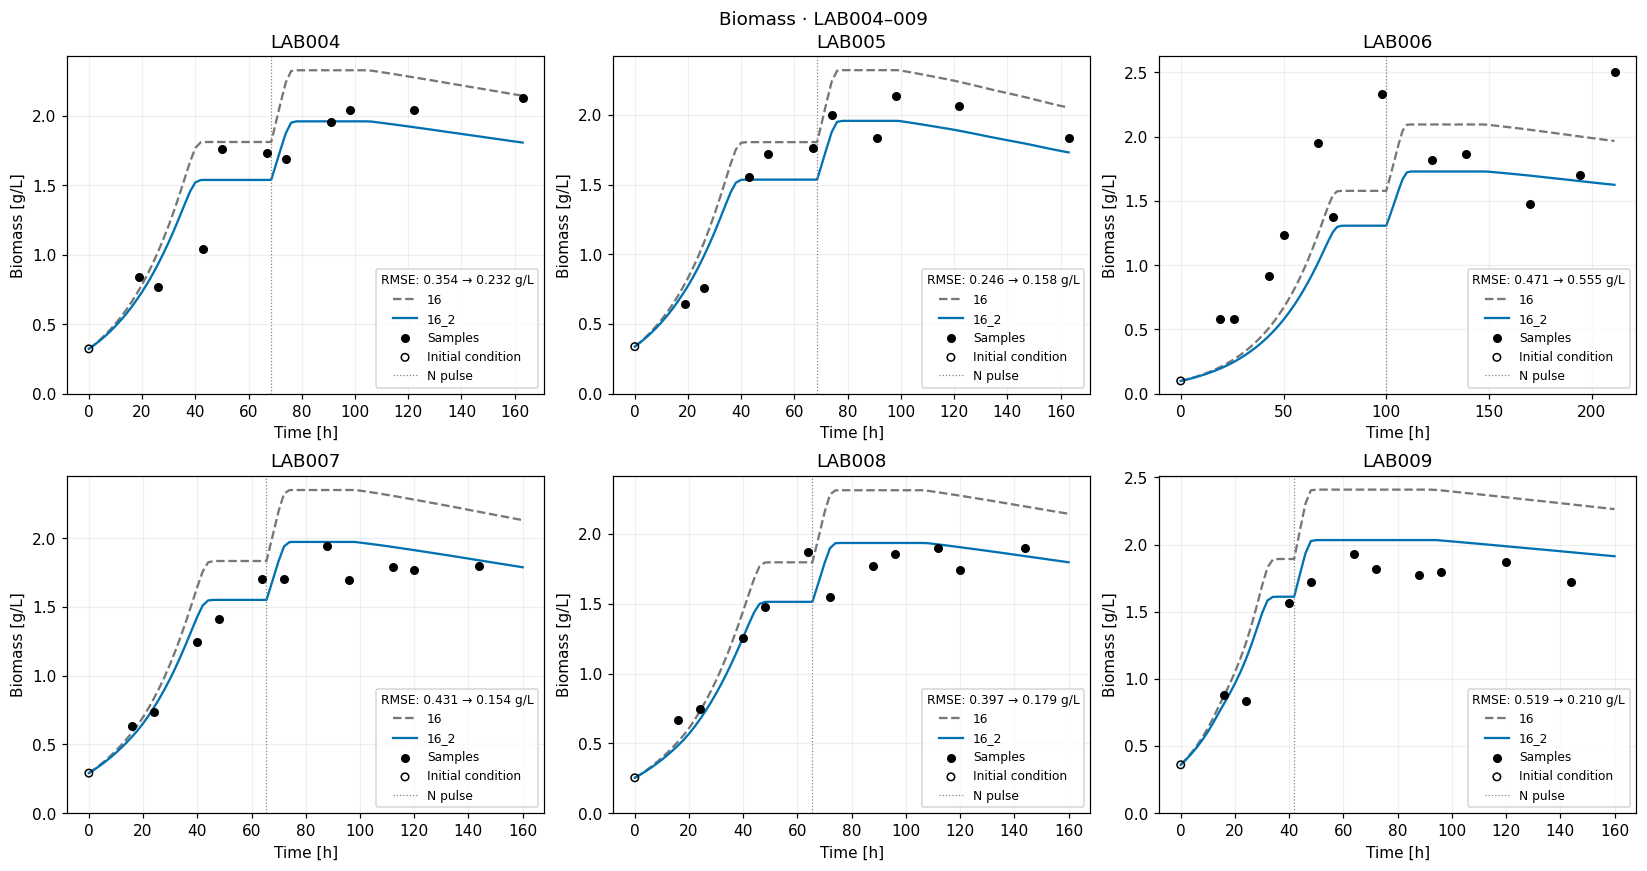

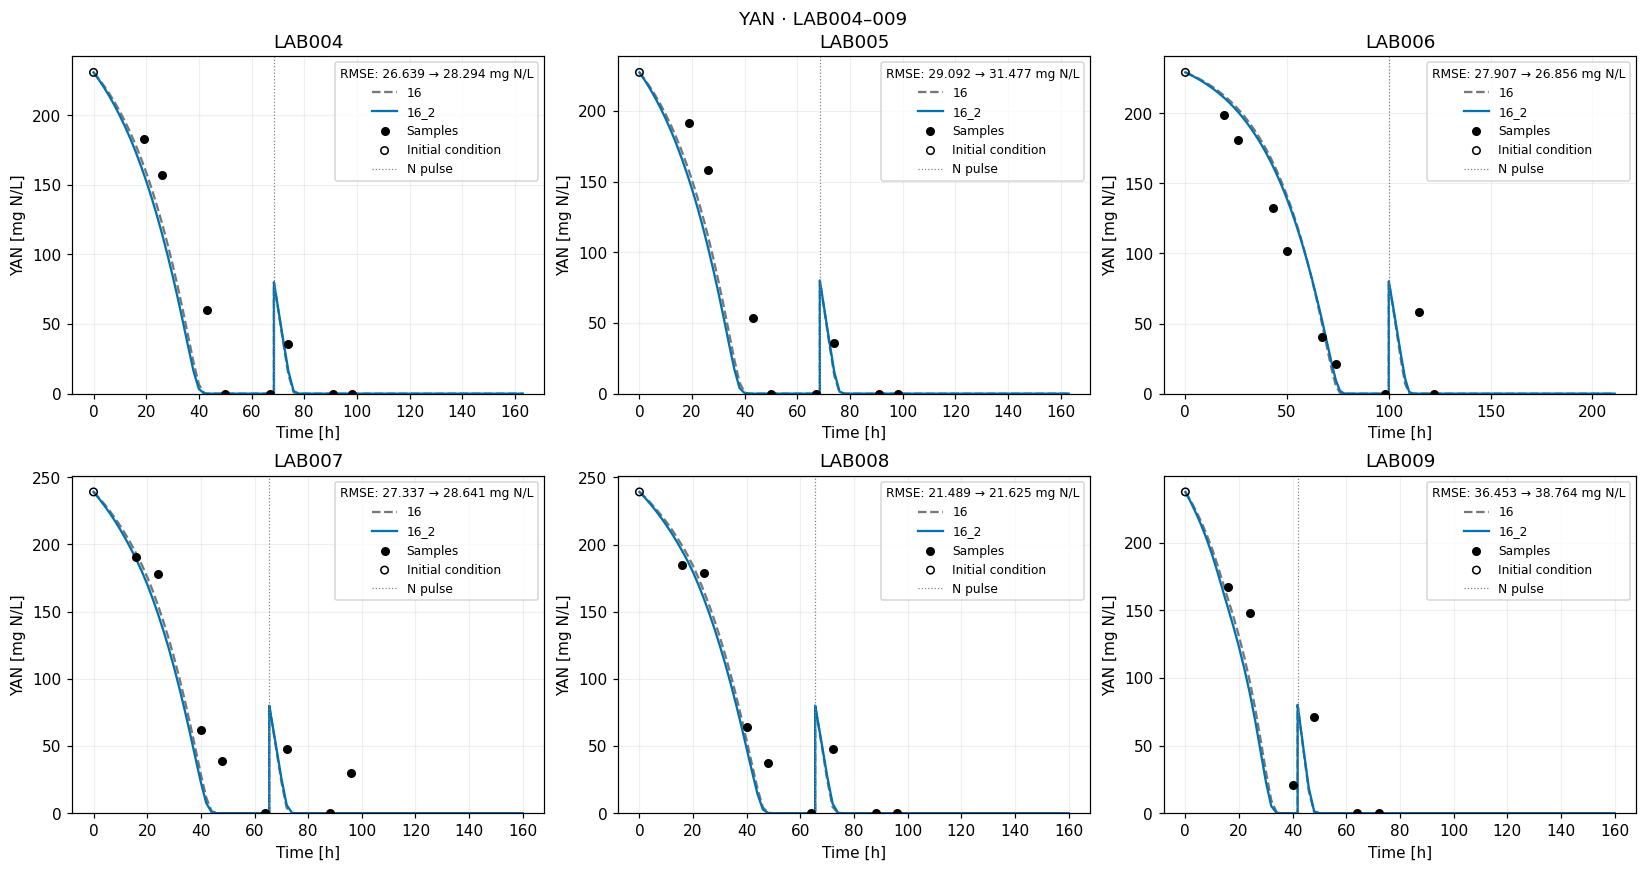

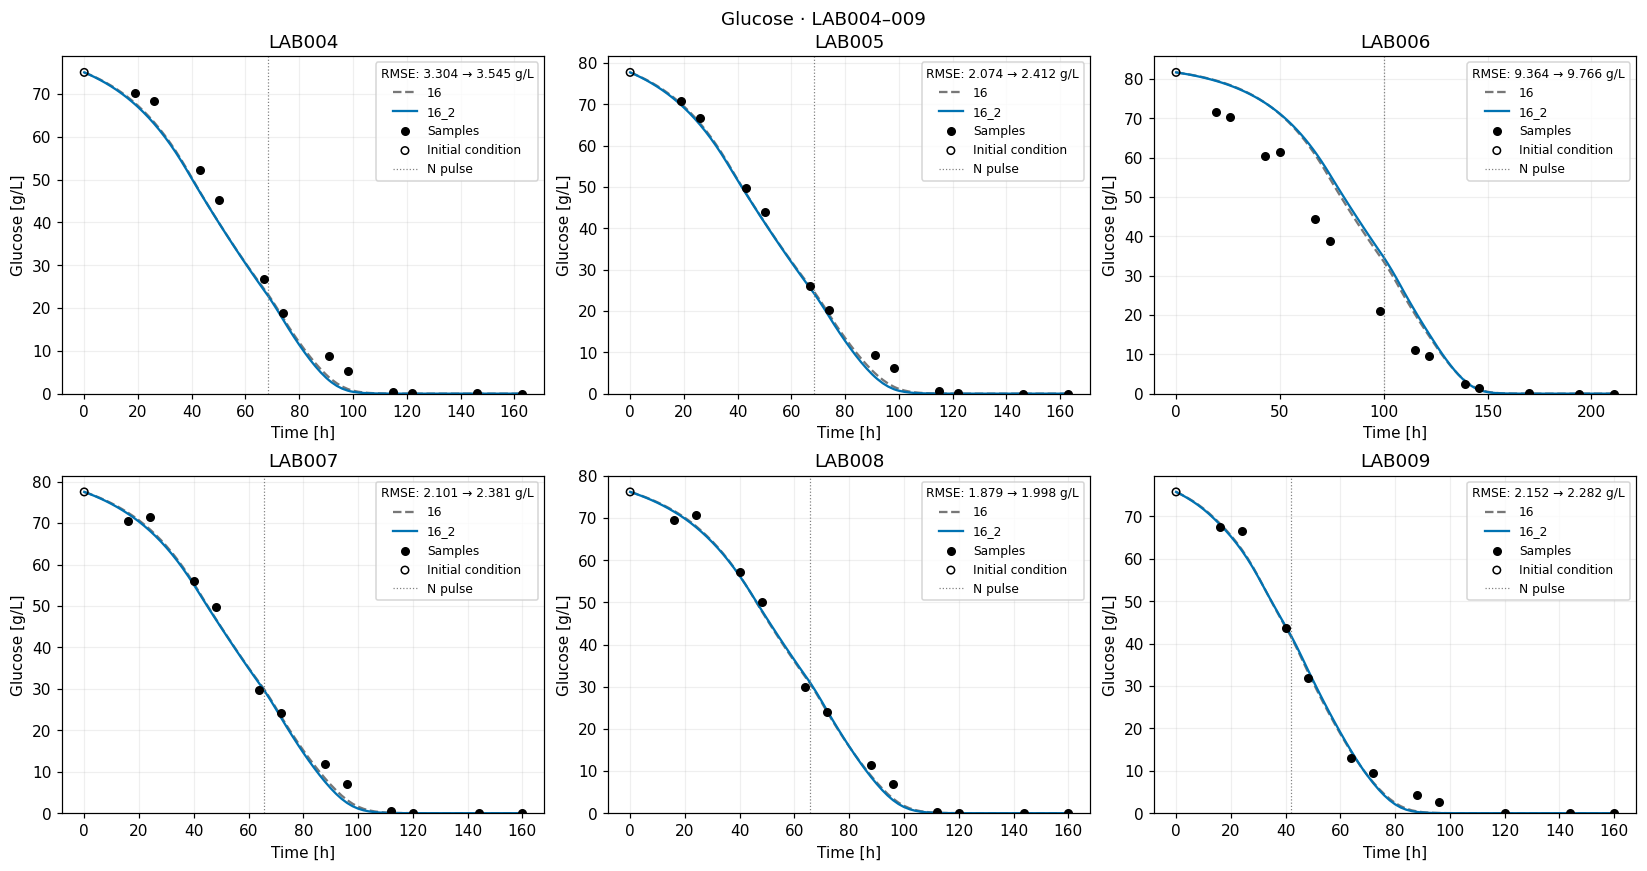

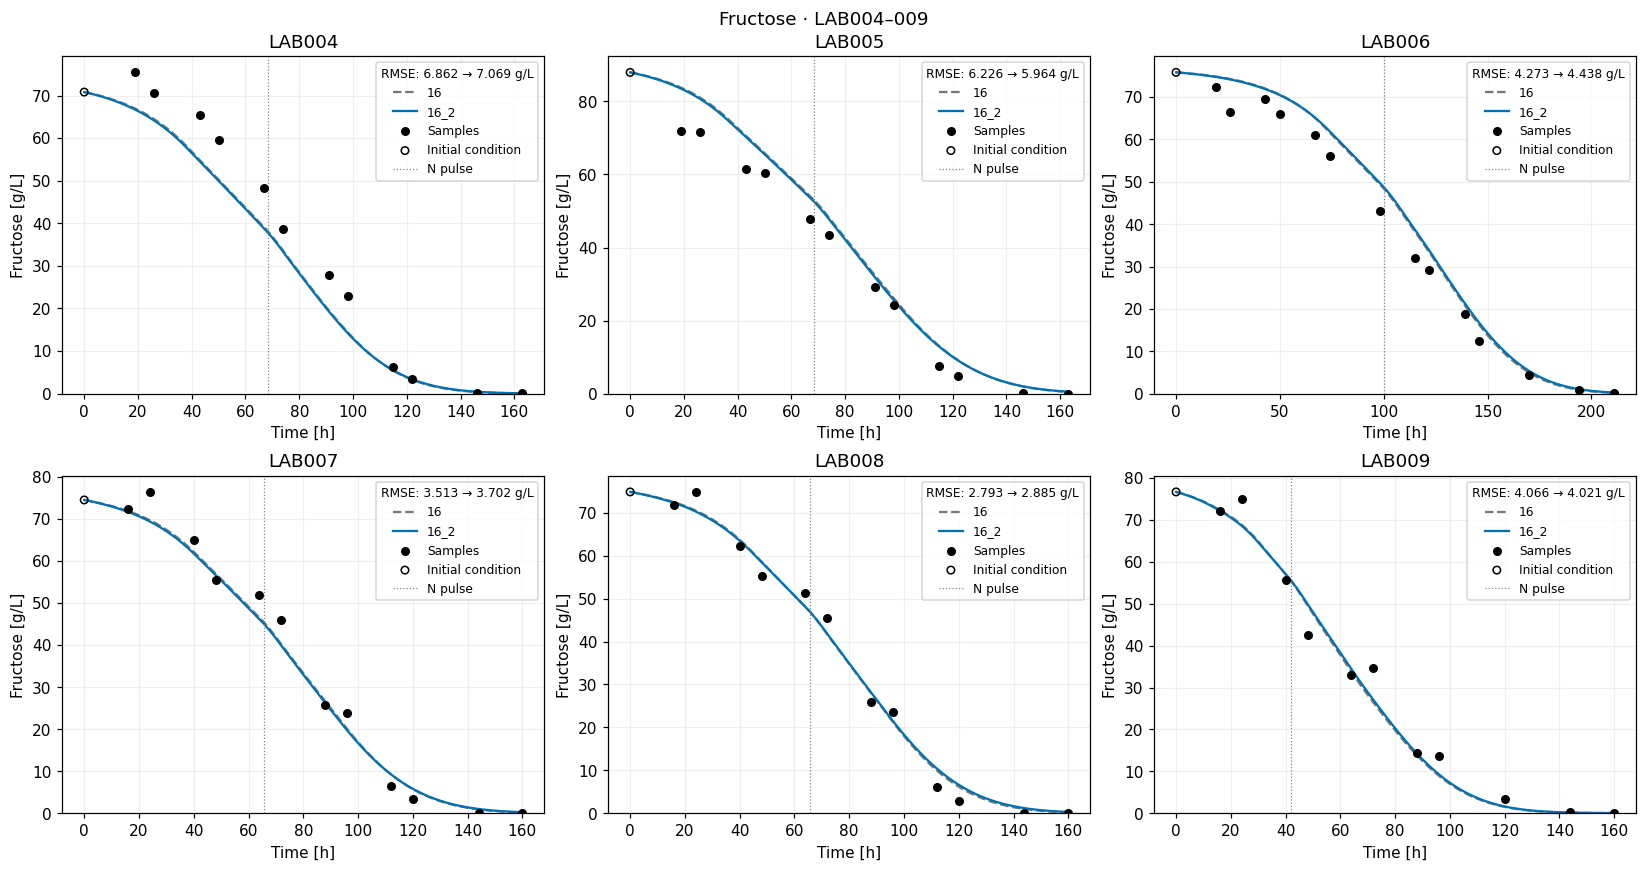

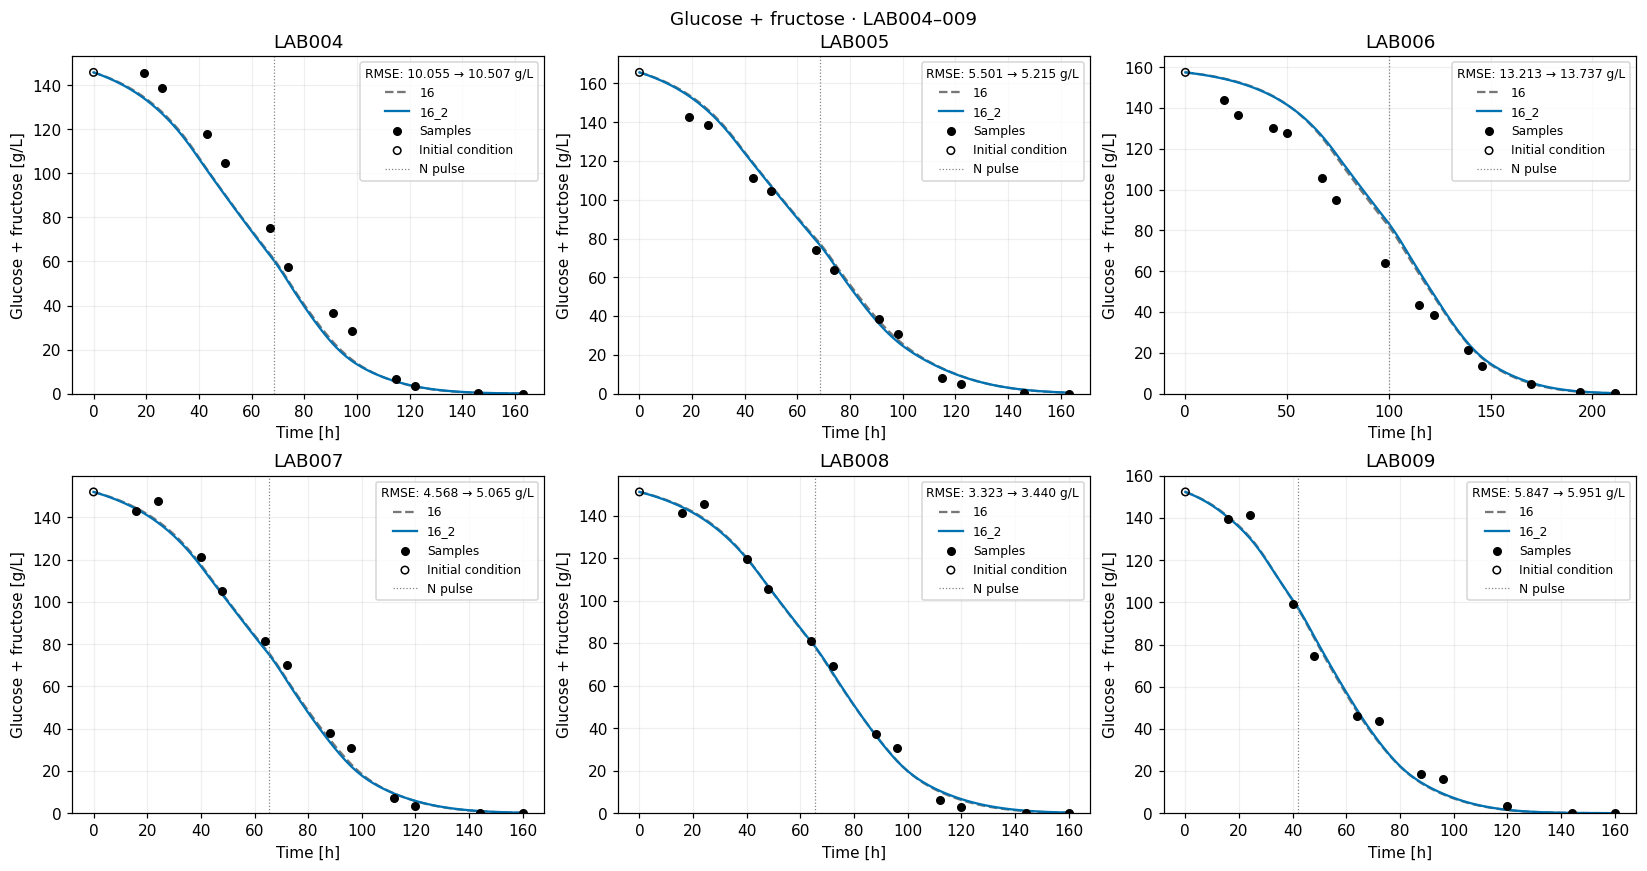

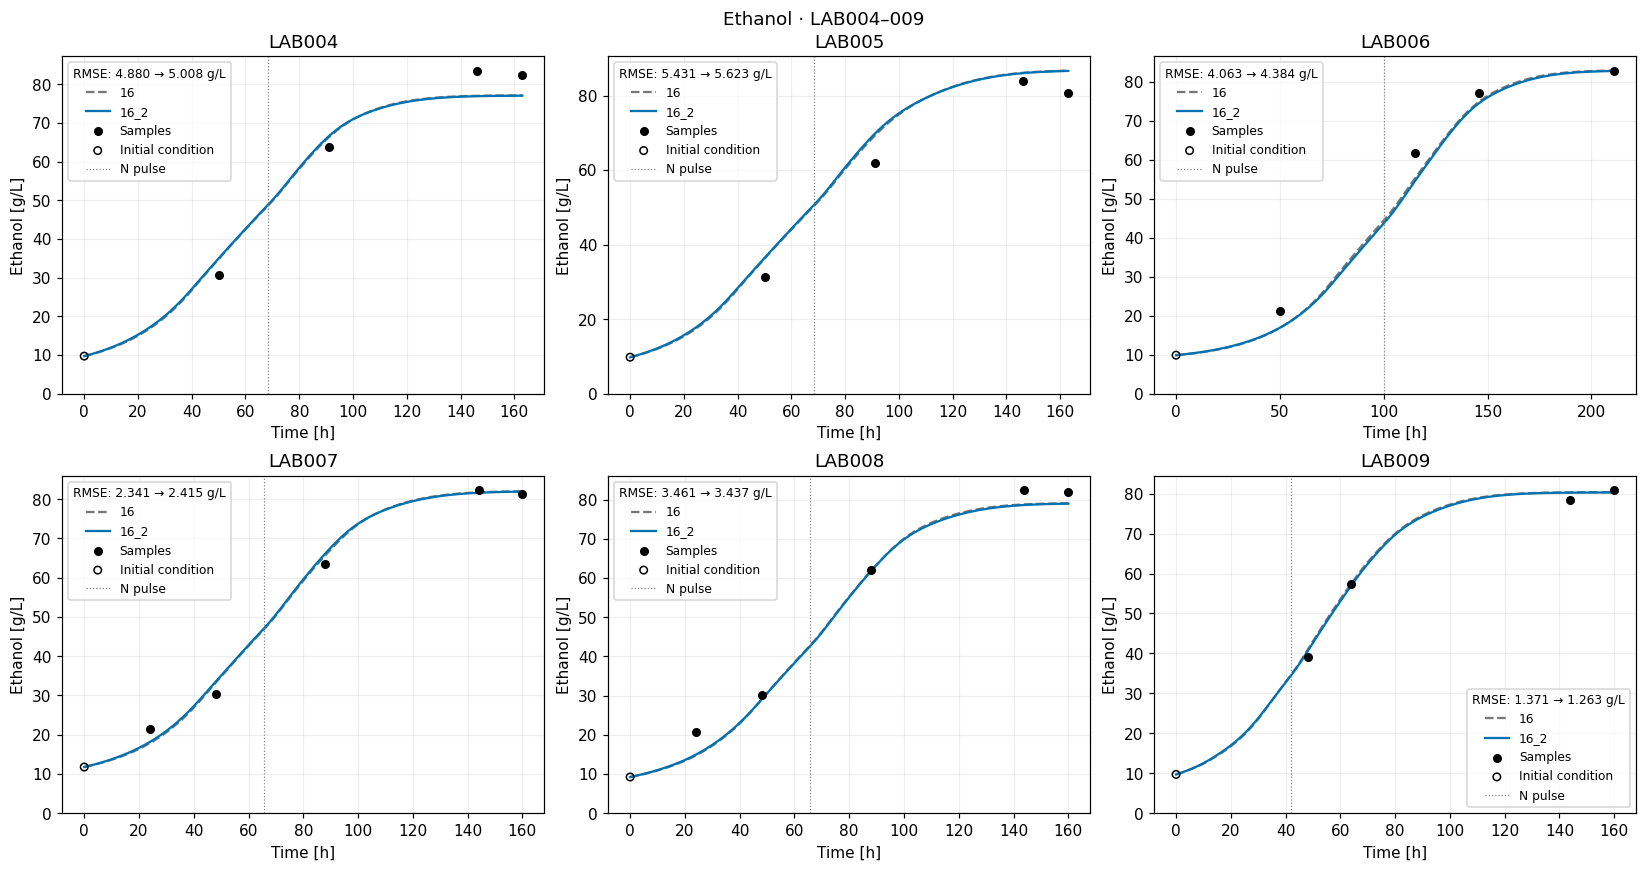

In [5]:
for state, title, factor, unit in (
    ("X", "Biomass", 1., "g/L"),
    ("N", "YAN", 1000., "mg N/L"),
    ("G", "Glucose", 1., "g/L"),
    ("F", "Fructose", 1., "g/L"),
    ("GF", "Glucose + fructose", 1., "g/L"),
    ("E", "Ethanol", 1., "g/L"),
):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, b in zip(axes.flat, treated):
        values = b.observations["G"] + b.observations["F"] if state == "GF" else b.observations[state]
        initial = b.initials["G"] + b.initials["F"] if state == "GF" else b.initials[state]
        mask = np.isfinite(values) & (b.time > 0)
        for model, color, style in (("16", "#777777", "--"), ("16_2", "#0072B2", "-")):
            frame = with_jumps(predictions[model][b.batch])
            ax.plot(frame.index, factor * frame[state], color=color, ls=style, label=model)
        ax.scatter(b.time[mask], factor * values[mask], c="black", s=24,
                   label="Samples", zorder=4)
        ax.scatter([0], [factor * initial], facecolors="none", edgecolors="black",
                   s=24, label="Initial condition", zorder=4)
        ax.axvline(b.pulses["N"][0][0], color="gray", ls=":", lw=.8, label="N pulse")
        ax.set(title=b.batch, xlabel="Time [h]", ylabel=f"{title} [{unit}]", ylim=(0, None))
        ax.grid(alpha=.2)
        if mask.any():
            rmse16, rmse_new = [
                np.sqrt(np.mean((curves[b.batch][state].to_numpy()[mask] - values[mask])**2)) * factor
                for curves in predictions.values()
            ]
            title_legend = f"RMSE: {rmse16:.3f} → {rmse_new:.3f} {unit}"
        else:
            title_legend = None
        ax.legend(fontsize=8, title=title_legend, title_fontsize=8)
    fig.suptitle(f"{title} · LAB004–009")
    fig.tight_layout(pad=.8)
    plt.show()


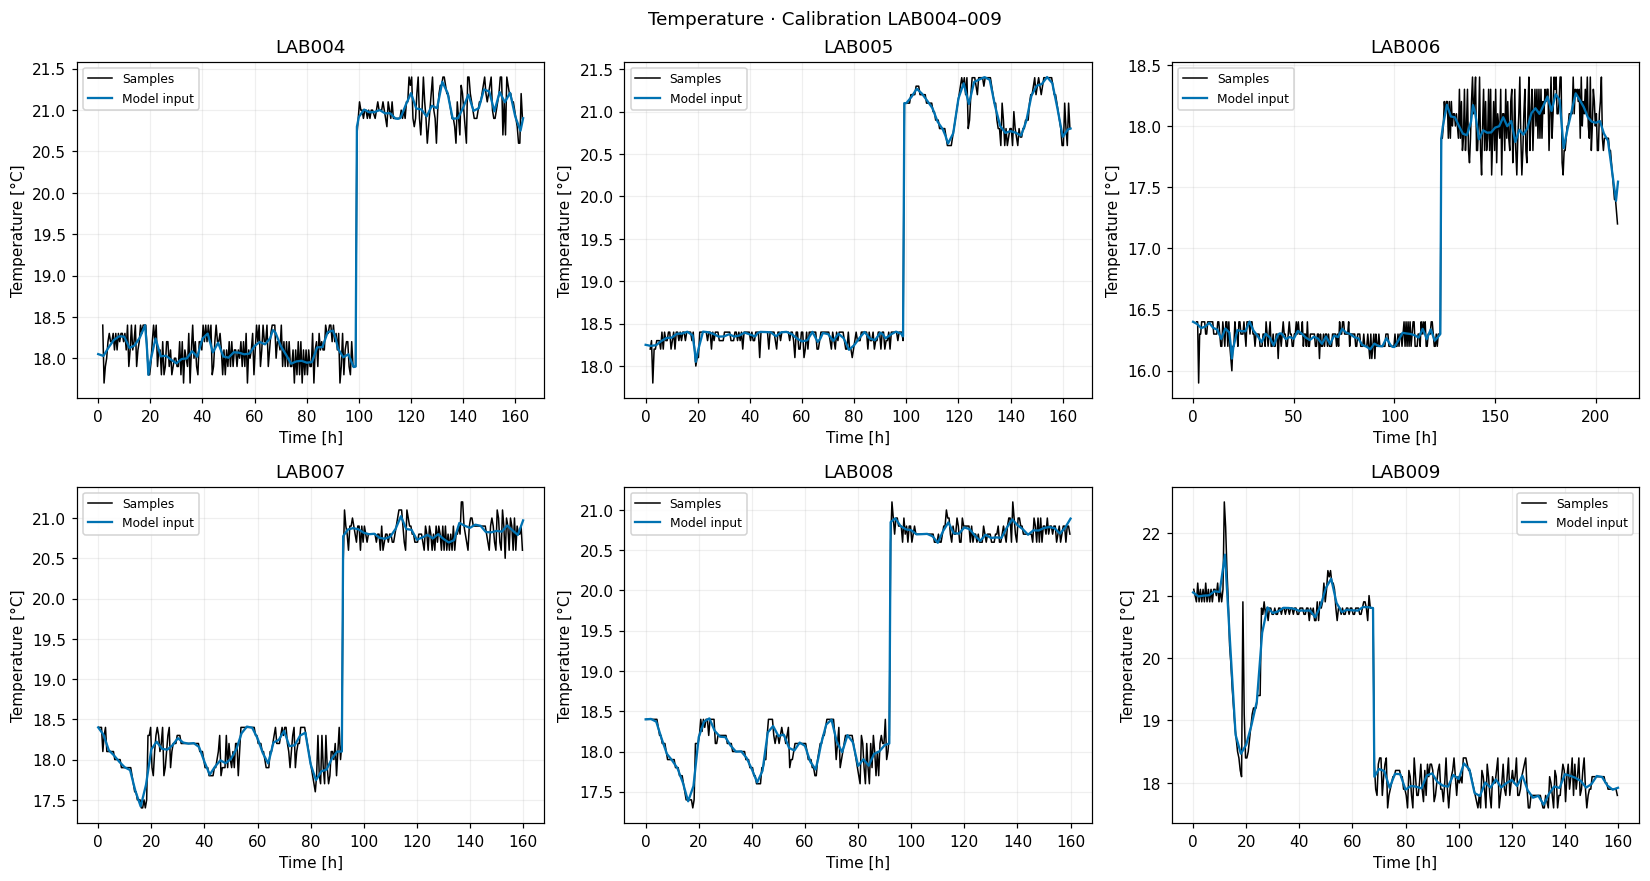

In [6]:
# Perfiles térmicos medidos de los entrenamientos y perfil filtrado usado por las simulaciones.
fig,axs=plt.subplots(2,3,figsize=(15,8))
for ax,b in zip(axs.flat,treated):
 p=profiles[b.batch].loc[lambda p: p.t_h.between(b.time[0], b.time[-1])]
 ax.plot(p.t_h,p['T'],c='black',lw=1,label='Samples')
 ax.plot(b.time,b.temperature_c,c='#0072B2',lw=1.5,label='Model input')
 assert len(p)==len(p.dropna(subset=['t_h','T'])) and np.isfinite(b.temperature_c).all()
 assert set(ax.get_legend_handles_labels()[1])=={'Samples','Model input'}
 ax.set(title=b.batch,xlabel='Time [h]',ylabel='Temperature [°C]');ax.grid(alpha=.2)
fig.suptitle('Temperature · Calibration LAB004–009',y=.99);fig.tight_layout(pad=.7,h_pad=1.2,w_pad=.9)
for ax in axs.flat:
 hs,ls=ax.get_legend_handles_labels();unique=dict(zip(ls,hs))
 ax.legend(unique.values(),unique.keys(),loc='best',fontsize=8,framealpha=.85)
assert not fig.legends;plt.show()

## Temperatura, química y CO₂ en LAB016–024

Se usa la preparación de datos y la solubilidad variable del 16. Los paneles de validación LAB016–024 superponen las trayectorias del 16 (gris) y 16_2 (azul) con las mismas entradas y la pareja G/F archivada del 16, kLa = 0,15007991 h⁻¹ y ganancia = 0,64606439. El perfil de MSE muestra sensibilidad a kLa con esa ganancia fija. Las trayectorias usan exclusivamente la pareja archivada. Las referencias de azúcar por densidad se muestran con los mismos criterios del 16.

LAB022–024 usan el perfil térmico de referencia de LAB016–021, igual que en el 17_2: mediana por minuto, interpolación de huecos de hasta dos minutos y, por tramo continuo, mediana centrada de 20 minutos seguida de media centrada de 45 minutos. La temperatura filtrada se interpola a la malla del modelo y se usa en las dos predicciones.

,LAB,X,N,G,F,E,pulsos,corte_h
0,LAB019,0.283162,0.230025,79.190000,78.970000,12.075372,"((64.33333333333277, 0.08648648648648648),)",166.000000
1,LAB020,0.153342,0.225556,77.940000,79.520000,11.917524,"((71.66666666666694, 0.08888888888888889),)",172.333333
2,LAB021,0.270000,0.231202,80.190000,81.040000,11.759676,"((47.5, 0.08648648648648648),)",166.000000
3,LAB016,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93555555555583, 0.14),)",151.100000
4,LAB017,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.933611111110835, 0.28),)",141.000000
5,LAB018,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93166666666694, 0.14),)",141.000000


,LAB,rol,n,RMSE,sesgo
0,LAB019,Calibración gas,166,0.116474,0.012518
1,LAB020,Calibración gas,172,0.076002,0.031133
2,LAB021,Calibración gas,166,0.191589,0.016794
3,LAB016,Holdout gas,152,0.133824,-0.000037
4,LAB017,Holdout gas,141,0.134853,-0.037598
5,LAB018,Holdout gas,141,0.124677,-0.013121


,RMSE,sesgo
rol,,
Calibración gas,0.128022,0.020148
Holdout gas,0.131118,-0.016919


,LAB,inicio_5g_h,completa_10g_h
0,LAB019,11.3,19.1
1,LAB020,19.6,31.3
2,LAB021,10.5,17.3
3,LAB016,7.6,13.2
4,LAB017,7.7,13.4
5,LAB018,7.6,13.2


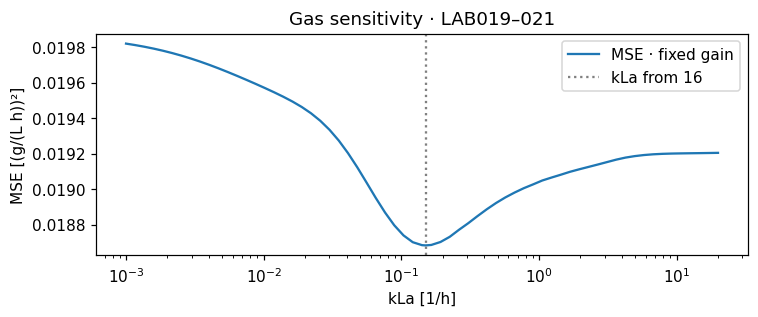

In [7]:
from wine_fermentation.models.historical.calibration import load
from wine_fermentation.comparison import observations, chemical_observations, CHEMICAL_COLUMNS

v=load(ROOT);LABS=['LAB019','LAB020','LAB021','LAB016','LAB017','LAB018'];TRAIN=LABS[:3];HOLD=LABS[3:]
raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','remaining_volume_L','co2_raw_g_l_h']);obs=observations(raw)
batches={};volumes={};entry=[]
for lab in LABS:
 b=v.batches[lab];ev=raw.loc[raw.lab.eq(lab)&raw.record_kind.eq('withdrawal_after')].sort_values('time_h');et=ev.time_h.to_numpy();vv=ev.remaining_volume_L.to_numpy()
 def volume(t,et=et,vv=vv):return np.r_[2.,vv][np.searchsorted(et,np.asarray(t),side='right')]
 volumes[lab]=volume
 if lab in TRAIN:b=replace(b,pulses={**b.pulses,'N':tuple((t,d*2/float(volume(t))) for t,d in b.pulses['N'])})
 if lab=='LAB017':b=replace(b,pulses={**b.pulses,'N':((min(t for t,d in b.pulses['N']),sum(d for t,d in b.pulses['N'])),)})
 if lab=='LAB021':b=replace(b,initials={**b.initials,'X':9.*.03})
 batches[lab]=b
 entry.append(dict(LAB=lab,**b.initials,pulsos=b.pulses['N'],corte_h=v.horizons[lab]))
 obs[lab]=obs[lab].loc[obs[lab].time_h.between(0,v.horizons[lab])].copy()
display(pd.DataFrame(entry))


def build_curves(parameters):
 cores,caches,activation={},{},{}
 for lab,b in batches.items():
  f=simulate(b,parameters);cores[lab]=f;f=with_jumps(f)
  tt=np.unique(np.r_[np.arange(0,float(f.index[-1]),.1),f.index[-1]])
  rates=[]
  for t in tt:
   y=[np.interp(t,f.index,f[s]) for s in kin.STATE_NAMES];q=kin.kinetic_terms(parameters,kin.temperature_at(b,t),*y)
   if y[2]<=0 or y[3]<=0:q['mu']=0.
   rates.append((q['mu']/12.72+(q['beta_g']+q['beta_f'])/1.05)*y[0])
  caches[lab]=(tt,np.asarray(rates))
  consumed=b.initials['G']+b.initials['F']-np.interp(tt,f.index,f.GF)
  z=np.clip((consumed-5.)/5.,0.,1.);activation[lab]=z*z*(3.-2.*z)
  assert np.all(activation[lab][consumed<=5.]==0) and np.all(activation[lab][consumed>=10.]==1)
 return cores,caches,activation

PCO2_BAR=1.0
ETHANOL_G_L_PER_VOL_PERCENT=7.8924
GAS_BOUNDS={'kLa':(0.001,20.),'gain':(.05,3.)}

def saturation(T,E,S):
 a=np.maximum(E,0)/ETHANOL_G_L_PER_VOL_PERCENT
 return 3.295*np.exp((7e-5*a-.02905)*np.asarray(T)-.0179*a-.00111*np.maximum(S,0))*PCO2_BAR

def configure_gas(frames,single=False):
 global gas_equilibrium
 gas_equilibrium={}
 for lab,f in frames.items():
  times=caches[lab][0]
  ff=plotframe_s(f) if single else with_jumps(f)
  T=np.array([kin.temperature_at(batches[lab],float(t)) for t in times])
  E=np.interp(times,ff.index,ff.E)
  S=np.interp(times,ff.index,ff.S if single else ff.GF)
  gas_equilibrium[lab]=(T,E,S,saturation(T,E,S))

def gas(lab,k,gain=1,activated=True,substeps=1):
 t,source=caches[lab]
 source=source*activation[lab] if activated else source.copy()
 T,E,S,sat=gas_equilibrium[lab]
 cd=np.zeros(len(t));qout=np.zeros(len(t));acc=np.zeros(len(t))
 qout[0]=max(source[0]-k*sat[0],0.)
 for i,dt in enumerate(np.diff(t),1):
  qp=(source[i-1]+source[i])/2;previous=cd[i-1];current=previous
  for j in range(substeps):
   h=dt/substeps;fraction=(j+.5)/substeps;cs=sat[i-1]*(1-fraction)+sat[i]*fraction
   if current>cs:
    current=cs+(current-cs)*np.exp(-k*h)
   else:
    D=cs-current
    if qp<=0 or D<=0:delta=0.
    elif k*D<=qp:delta=D*(-np.expm1(-k*h))
    else:
     crossing=(D-qp/k)/qp;linear=min(h,crossing);delta=qp*linear
     if crossing<h:delta+=(qp/k)*(-np.expm1(-k*(h-crossing)))
    current+=delta
  cd[i]=current;acc[i]=(current-previous)/dt;qout[i]=qp-acc[i]
 assert cd.min()>=-1e-12 and qout.min()>-1e-10
 assert np.max(abs(np.diff(cd)-np.diff(t)*((source[:-1]+source[1:])/2-qout[1:])))<1e-10
 return pd.DataFrame(dict(qprod=source,Cd=cd,Csat=sat,T=T,E=E,S=S,qgas=qout,qpred=gain*qout),index=t)

cores,caches,activation=build_curves(theta)
configure_gas(cores)
KLA, GAIN = .15007991020720535, .6460643588058115

curves={lab:gas(lab,KLA,GAIN) for lab in LABS};metrics=[]
for lab in LABS:
 o=obs[lab];f=curves[lab];e=np.interp(o.time_h,f.index,f.qpred)-o.co2_raw_g_l_h
 metrics.append(dict(LAB=lab,rol='Calibración gas' if lab in TRAIN else 'Holdout gas',n=len(o),RMSE=np.sqrt(np.mean(e*e)),sesgo=np.mean(e)))
metrics=pd.DataFrame(metrics);display(metrics);display(metrics.groupby('rol')[['RMSE','sesgo']].mean())

display(pd.DataFrame([dict(LAB=lab,inicio_5g_h=float(caches[lab][0][np.flatnonzero(activation[lab]>0)[0]]),completa_10g_h=float(caches[lab][0][np.flatnonzero(activation[lab]>=1)[0]])) for lab in LABS]))

def gas_mse_at_fixed_gain(kla):
    errors = []
    for lab in TRAIN:
        frame = gas(lab, kla, GAIN)
        sample = obs[lab]
        error = np.interp(sample.time_h, frame.index, frame.qpred) - sample.co2_raw_g_l_h
        errors.append(np.mean(error**2))
    return np.mean(errors)

kla_grid = np.unique(np.r_[np.geomspace(*GAS_BOUNDS["kLa"], 65), KLA])
profile_mse = np.array([gas_mse_at_fixed_gain(kla) for kla in kla_grid])
fig, ax = plt.subplots(figsize=(7, 3))
ax.semilogx(kla_grid, profile_mse, label="MSE · fixed gain")
ax.axvline(KLA, color="gray", ls=":", label="kLa from 16")
ax.set(xlabel="kLa [1/h]", ylabel="MSE [(g/(L h))²]", title="Gas sensitivity · LAB019–021")
ax.legend()
fig.tight_layout()
plt.show()

from types import FunctionType

cores16, caches16, activation16 = build_curves(theta16)
reference_gas_context = dict(globals(), caches=caches16, activation=activation16)
FunctionType(configure_gas.__code__, reference_gas_context, argdefs=configure_gas.__defaults__)(cores16)
gas16 = FunctionType(gas.__code__, reference_gas_context, argdefs=gas.__defaults__)
curves16 = {lab: gas16(lab, KLA, GAIN) for lab in LABS}


In [8]:
HOLDOUT_MODEL = 'G/F'
HOLDOUT_SINGLE = False
HOLDOUT_GAS_PARAMS = (KLA, GAIN)

import nbformat
from types import FunctionType
from wine_fermentation.models.historical.calibration import local_to_utc, temperature_signals

instrument = json.loads((ROOT / "configs/co2_instrument.json").read_text(encoding="utf-8"))
prep_path = ROOT / "notebooks/preparing_data/lab022_024_data.source.ipynb"
prep_nb = nbformat.read(prep_path, as_version=4)
sample_code = [cell.source for cell in prep_nb.cells if cell.cell_type == "code" and
               any(marker in cell.source for marker in
                   ("workbook = data_dir /", "y15_sources = {", "oculyze_frames = []"))]
assert len(sample_code) == 3
prepared = {}
for source in sample_code:
    python_source = "\n".join(line for line in source.splitlines() if not line.startswith("%"))
    exec(compile(python_source, str(prep_path), "exec"), prepared)

holdout_labs = prepared["labs"]
holdout_biomass = prepared["oculyze"].assign(X_g_L=lambda f: .03 * f["Viable concentration"])
holdout_chemistry = prepared["chemistry"]
holdout_nutrition = (prepared["nutrition"] - prepared["inoculation"]).dt.total_seconds() / 3600
holdout_horizon = 190.
# Dosis confirmada por lote. Equivalente de YAN de SFX y fracción de N en FDA.
pulse_mass_n_g = 1.0 * .10 + .4 * (2 * 14.007 / 132.1)

reactors = prepared["experiments"]["Fermentador"]
reactor_map = pd.Series(reactors.index, index=reactors)
def read_holdout_backup(filename, *values, hours_before=0.):
    frame = pd.read_csv(prepared["data_dir"] / filename,
                        usecols=["timestamp", "fermentador", *values], parse_dates=["timestamp"])
    frame["lab"] = frame["fermentador"].map(reactor_map)
    frame["h"] = (frame["timestamp"] - frame["lab"].map(prepared["inoculation"])).dt.total_seconds() / 3600
    return frame.loc[frame["h"].ge(-hours_before)].sort_values("h")

holdout_temperature = read_holdout_backup("backup_global_temperatura.csv", "T", "SP", hours_before=6.)
holdout_temperature["timestamp"] = local_to_utc(holdout_temperature["timestamp"])
holdout_temperature_profiles = {}
holdout_raw_flow = read_holdout_backup("backup_global_co2.csv", "flow_sccm")
mass_factor = 44.0095 * 60 * instrument["co2_correction_factor"] / (1000 * 24.16)
holdout_batches, holdout_flow, pulse_rows = {}, {}, []
for lab in holdout_labs:
    samples = prepared["offline"].loc[prepared["offline"]["lab"].eq(lab)]
    withdrawals = samples.loc[samples["Observaciones"].eq("se quitan 50ml"), "hours"].to_numpy()
    initial_volume = float(prepared["experiments"].at[lab, "Volumen_Inicial_L"].removesuffix("L"))
    pulse_h = holdout_nutrition[lab]
    pulse_volume = initial_volume - .05 * np.searchsorted(withdrawals, pulse_h, side="right")
    pulse_n = pulse_mass_n_g / pulse_volume
    start_sample = holdout_biomass.loc[holdout_biomass["lab"].eq(lab) &
                                       holdout_biomass["sample"].eq("01")].iloc[0]
    start = float(start_sample["hours"])
    assert start == .25
    chem = holdout_chemistry.loc[holdout_chemistry["lab"].eq(lab)]
    initial = chem.loc[chem["sample"].eq("01")].iloc[0]
    initials = {"X": start_sample["X_g_L"], "N": initial["YAN for plot"] / 1000,
                "G": initial["GLUCOSE-320"], "F": initial["Fructose (derived)"], "E": 10.010194}
    biomass_h = holdout_biomass.loc[holdout_biomass["lab"].eq(lab), "hours"]
    # Se incluyen las horas de muestreo para evaluar la solución directamente.
    times = np.unique(np.r_[np.arange(start, holdout_horizon, 1/12), holdout_horizon, pulse_h,
                           chem.loc[chem["hours"].ge(start), "hours"], biomass_h])
    temp = holdout_temperature.loc[holdout_temperature["lab"].eq(lab)]
    assert temp.timestamp.is_unique and temp["h"].min() <= start and temp["h"].max() >= holdout_horizon
    t0 = local_to_utc([prepared["inoculation"][lab]])[0]
    profile = temperature_signals(temp, t0)
    holdout_temperature_profiles[lab] = profile
    filtered = profile.dropna(subset=[v.temperature_variant])
    assert filtered.time_h.min() <= start and holdout_horizon - filtered.time_h.max() <= 1/60 + 1e-8
    temp_c = np.interp(times, filtered.time_h, filtered[v.temperature_variant])
    holdout_batches[lab] = kin.BatchData(
        medium="natural", batch=lab, time=times, temperature_c=temp_c,
        pulses={"N": ((pulse_h, pulse_n),)}, observations={}, initials=initials,
    )
    pulse_rows.append({"LAB": lab, "Pulso [h]": pulse_h, "Volumen [L]": pulse_volume,
                       "Aporte [mg N/L]": 1000 * pulse_n})
    raw = holdout_raw_flow.loc[holdout_raw_flow["lab"].eq(lab) &
                               holdout_raw_flow["h"].gt(0)].copy()
    assert raw["h"].max() >= holdout_horizon
    raw["bin"] = np.ceil(raw["h"] / .5 - 1e-10).astype(int)
    sample_volumes = initial_volume - .05 * np.searchsorted(withdrawals, raw["h"], side="right")
    raw["mass_flow"] = raw["flow_sccm"] * mass_factor / sample_volumes
    means = {}
    for index, window in raw.groupby("bin"):
        end = index * .5
        if end > holdout_horizon:
            break
        gaps = np.diff(np.r_[end - .5, window["h"], end])
        valid = len(window) >= 30 and gaps.max() <= 2 / 60 + 1e-10
        means[end] = window["mass_flow"].mean() if valid else np.nan
    holdout_flow[lab] = pd.Series(means).reindex(np.arange(.5, holdout_horizon + .5, .5))
display(pd.DataFrame(pulse_rows).set_index("LAB").round(3))

,Pulso [h],Volumen [L],Aporte [mg N/L]
LAB,,,
LAB022,113.633,1.85,99.906
LAB023,113.783,1.85,99.906
LAB024,113.883,1.85,99.906


In [9]:
def simulate_holdout(batch, theta):
    # Se localiza el agotamiento antes de aplicar la ecuación sin crecimiento.
    sugar_indices = (2,) if HOLDOUT_SINGLE else (2, 3)
    def integrate_to_event(rhs, interval, initial, *, t_eval, **options):
        depleted = [index for index in sugar_indices if initial[index] <= 0]

        def after_depletion(t, state, index):
            state = state.copy()
            state[index] = 0.
            derivative = rhs(t, state)
            derivative[index] = 0.
            return derivative

        if len(depleted):
            return solve_ivp(lambda t, y: after_depletion(t, y, depleted[0]),
                             interval, initial, t_eval=t_eval, **options)

        def depletion_event(index):
            def event(t, state):
                return state[index]
            event.terminal = True
            event.direction = -1
            return event

        def before_depletion(t, state):
            # Las etapas de prueba pueden cruzar cero antes de que el solver localice el evento.
            state = state.copy()
            state[list(sugar_indices)] = np.maximum(state[list(sugar_indices)], np.finfo(float).tiny)
            return rhs(t, state)

        before = solve_ivp(before_depletion, interval, initial, t_eval=t_eval,
                           events=[depletion_event(index) for index in sugar_indices], **options)
        if before.status != 1:
            return before
        [event_index] = [i for i, hits in enumerate(before.t_events) if len(hits)]
        event_time = before.t_events[event_index][0]
        state = before.y_events[event_index][0].copy()
        index = sugar_indices[event_index]
        state[index] = 0.
        remaining = t_eval[t_eval > event_time]
        if not len(remaining):
            return before
        after = solve_ivp(lambda t, y: after_depletion(t, y, index),
                          (event_time, interval[1]), state, t_eval=remaining, **options)
        after.t = np.r_[before.t, after.t]
        before_states = np.asarray(before.y).reshape(len(initial), -1)
        after.y = np.column_stack([before_states, after.y])
        return after

    simulate_context = dict(globals(), solve_ivp=integrate_to_event)
    model_simulate, parameters = (simulate_s, ps) if HOLDOUT_SINGLE else (simulate, theta)
    return FunctionType(model_simulate.__code__, simulate_context)(batch, parameters)

def run_holdout(theta):
    holdout_kinetic, holdout_plot, holdout_source, holdout_activation = {}, {}, {}, {}
    for lab, batch in holdout_batches.items():
        trajectory = simulate_holdout(batch, theta)
        frame = plotframe_s(trajectory) if HOLDOUT_SINGLE else with_jumps(trajectory)
        holdout_kinetic[lab], holdout_plot[lab] = trajectory, frame
        if HOLDOUT_SINGLE:
            [(pulse_h, before, after)] = trajectory.attrs["jumps"]
        else:
            [jump] = trajectory.attrs["pulse_jumps"]
            pulse_h, before, after = jump["t"], jump["before"], jump["after"]
        np.testing.assert_allclose([pulse_h, after[1] - before[1]], batch.pulses["N"][0], atol=1e-12)
        times = np.r_[np.arange(batch.time[0], holdout_horizon, .1), holdout_horizon]
        source = []
        variables = ["X", "N", "S", "E"] if HOLDOUT_SINGLE else kin.STATE_NAMES
        for t in times:
            y = [np.interp(t, frame.index, frame[state]) for state in variables]
            if HOLDOUT_SINGLE:
                mu, fermentation, _, _ = terms_s(t, y, ps, batch)
            else:
                rates = kin.kinetic_terms(theta, kin.temperature_at(batch, t), *y)
                mu = rates["mu"] if y[2] > 0 and y[3] > 0 else 0.
                fermentation = rates["beta_g"] + rates["beta_f"]
            source.append((mu / 12.72 + fermentation / 1.05) * y[0])
        sugar = frame["S" if HOLDOUT_SINGLE else "GF"]
        consumed = sugar.iloc[0] - np.interp(times, frame.index, sugar)
        z = np.clip((consumed - 5.) / 5., 0., 1.)
        holdout_activation[lab] = z * z * (3. - 2. * z)
        holdout_source[lab] = (times, np.asarray(source))

    # El integrador de gas usa diccionarios globales. Cada ejecución del holdout recibe los suyos.
    gas_context = dict(globals(), batches=holdout_batches, caches=holdout_source, activation=holdout_activation)
    FunctionType(configure_gas.__code__, gas_context)(holdout_kinetic, HOLDOUT_SINGLE)
    predict_gas = FunctionType(gas.__code__, gas_context, argdefs=gas.__defaults__)
    holdout_gas = {lab: predict_gas(lab, *HOLDOUT_GAS_PARAMS) for lab in holdout_labs}
    holdout_mean_gas = {}
    for lab, curve in holdout_gas.items():
        times = curve.index.to_numpy()
        cumulative = np.r_[0., np.cumsum(np.diff(times) * curve["qpred"].to_numpy()[1:])]
        ends = holdout_flow[lab].index.to_numpy()
        ends = ends[ends - .5 >= times[0]]
        mean = (np.interp(ends, times, cumulative) - np.interp(ends - .5, times, cumulative)) / .5
        holdout_mean_gas[lab] = pd.Series(mean, index=ends)
    return holdout_kinetic, holdout_plot, holdout_gas, holdout_mean_gas

holdout_kinetic, holdout_plot, holdout_gas, holdout_mean_gas = run_holdout(theta)
holdout_kinetic16, holdout_plot16, holdout_gas16, holdout_mean_gas16 = run_holdout(theta16)


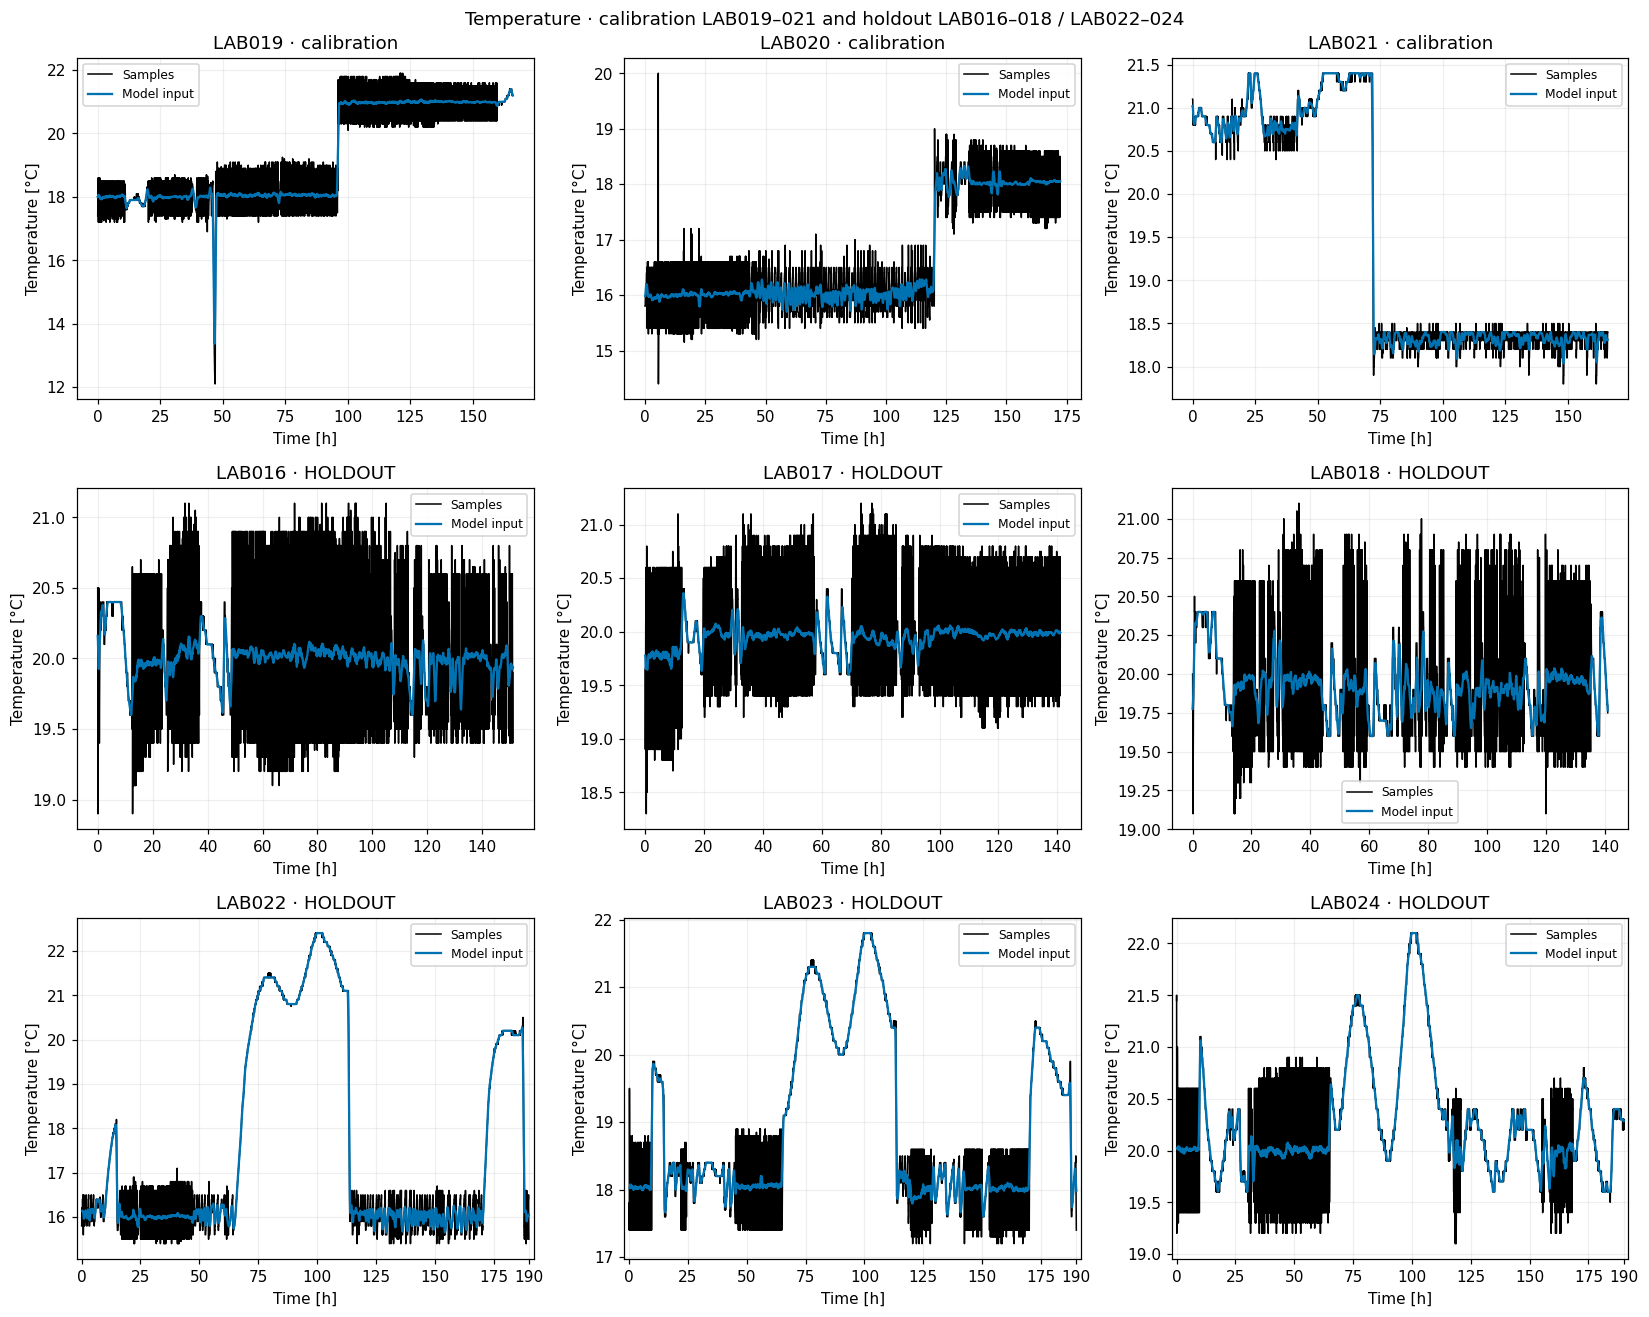

In [10]:
def temperature_panel(ax,lab,role,measured_t,measured,input_t,input_T):
 ax.plot(measured_t,measured,c='black',lw=1,label='Samples')
 ax.plot(input_t,input_T,c='#0072B2',lw=1.5,label='Model input')
 ax.set(title=lab+role,xlabel='Time [h]',ylabel='Temperature [°C]');ax.grid(alpha=.2)
 assert np.isfinite(np.asarray(measured,float)).any() and np.isfinite(np.asarray(input_T,float)).all()

# Perfiles térmicos LAB016–024 con la misma disposición de filas que la figura de CO₂.
fig,axs=plt.subplots(3,3,figsize=(15,12))
for ax,lab in zip(axs[:2].flat,LABS):
 tv=v.temperature[lab]
 batch=batches[lab];end=v.horizons[lab]
 measured=tv.loc[tv.time_h.between(0,end)]
 times=np.r_[batch.time[batch.time<end],end]
 model_input=np.interp(times,batch.time,batch.temperature_c)
 temperature_panel(ax,lab,' · calibration' if lab in TRAIN else ' · HOLDOUT',
                   measured.time_h,measured.raw_1min,times,model_input)
for ax,lab in zip(axs[-1],holdout_labs):
 profile=holdout_temperature_profiles[lab]
 measured=profile.loc[profile.time_h.between(0, holdout_horizon)]
 batch=holdout_batches[lab]
 temperature_panel(ax,lab,' · HOLDOUT',measured.time_h,measured.raw_1min,batch.time,batch.temperature_c)
 ax.set(xlim=(-2,holdout_horizon+2),xticks=[0,25,50,75,100,125,150,175,190])
fig.suptitle('Temperature · calibration LAB019–021 and holdout LAB016–018 / LAB022–024',y=.99);fig.tight_layout(pad=.7,h_pad=1.2,w_pad=.9)
for ax in axs.flat:
 hs,ls=ax.get_legend_handles_labels();unique=dict(zip(ls,hs))
 assert set(unique)=={'Samples','Model input'}
 ax.legend(unique.values(),unique.keys(),loc='best',fontsize=8,framealpha=.85)
assert not fig.legends;plt.show()

G+F from density = 2.5*(densidad g/L - 1000); comparación gráfica, no usada en el ajuste; se conservan valores negativos de la conversión.


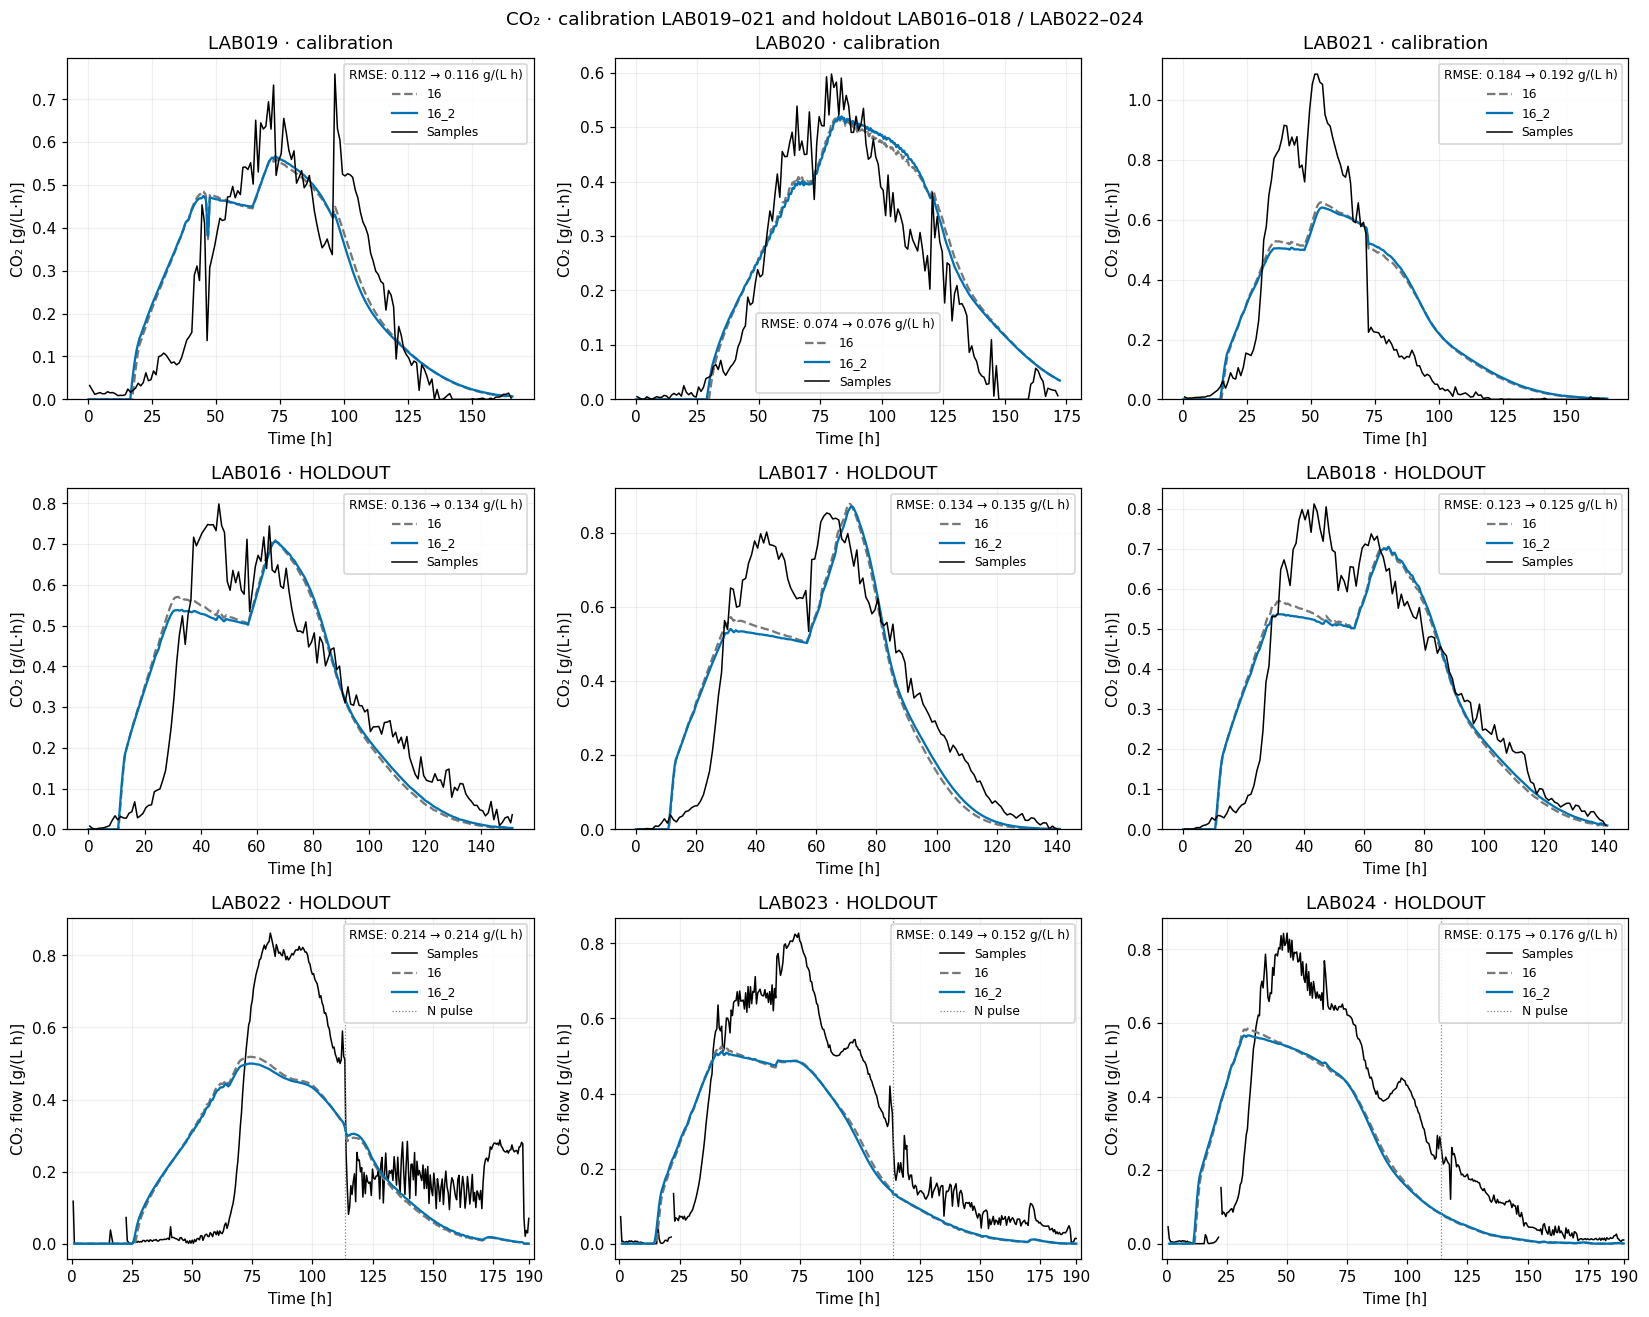

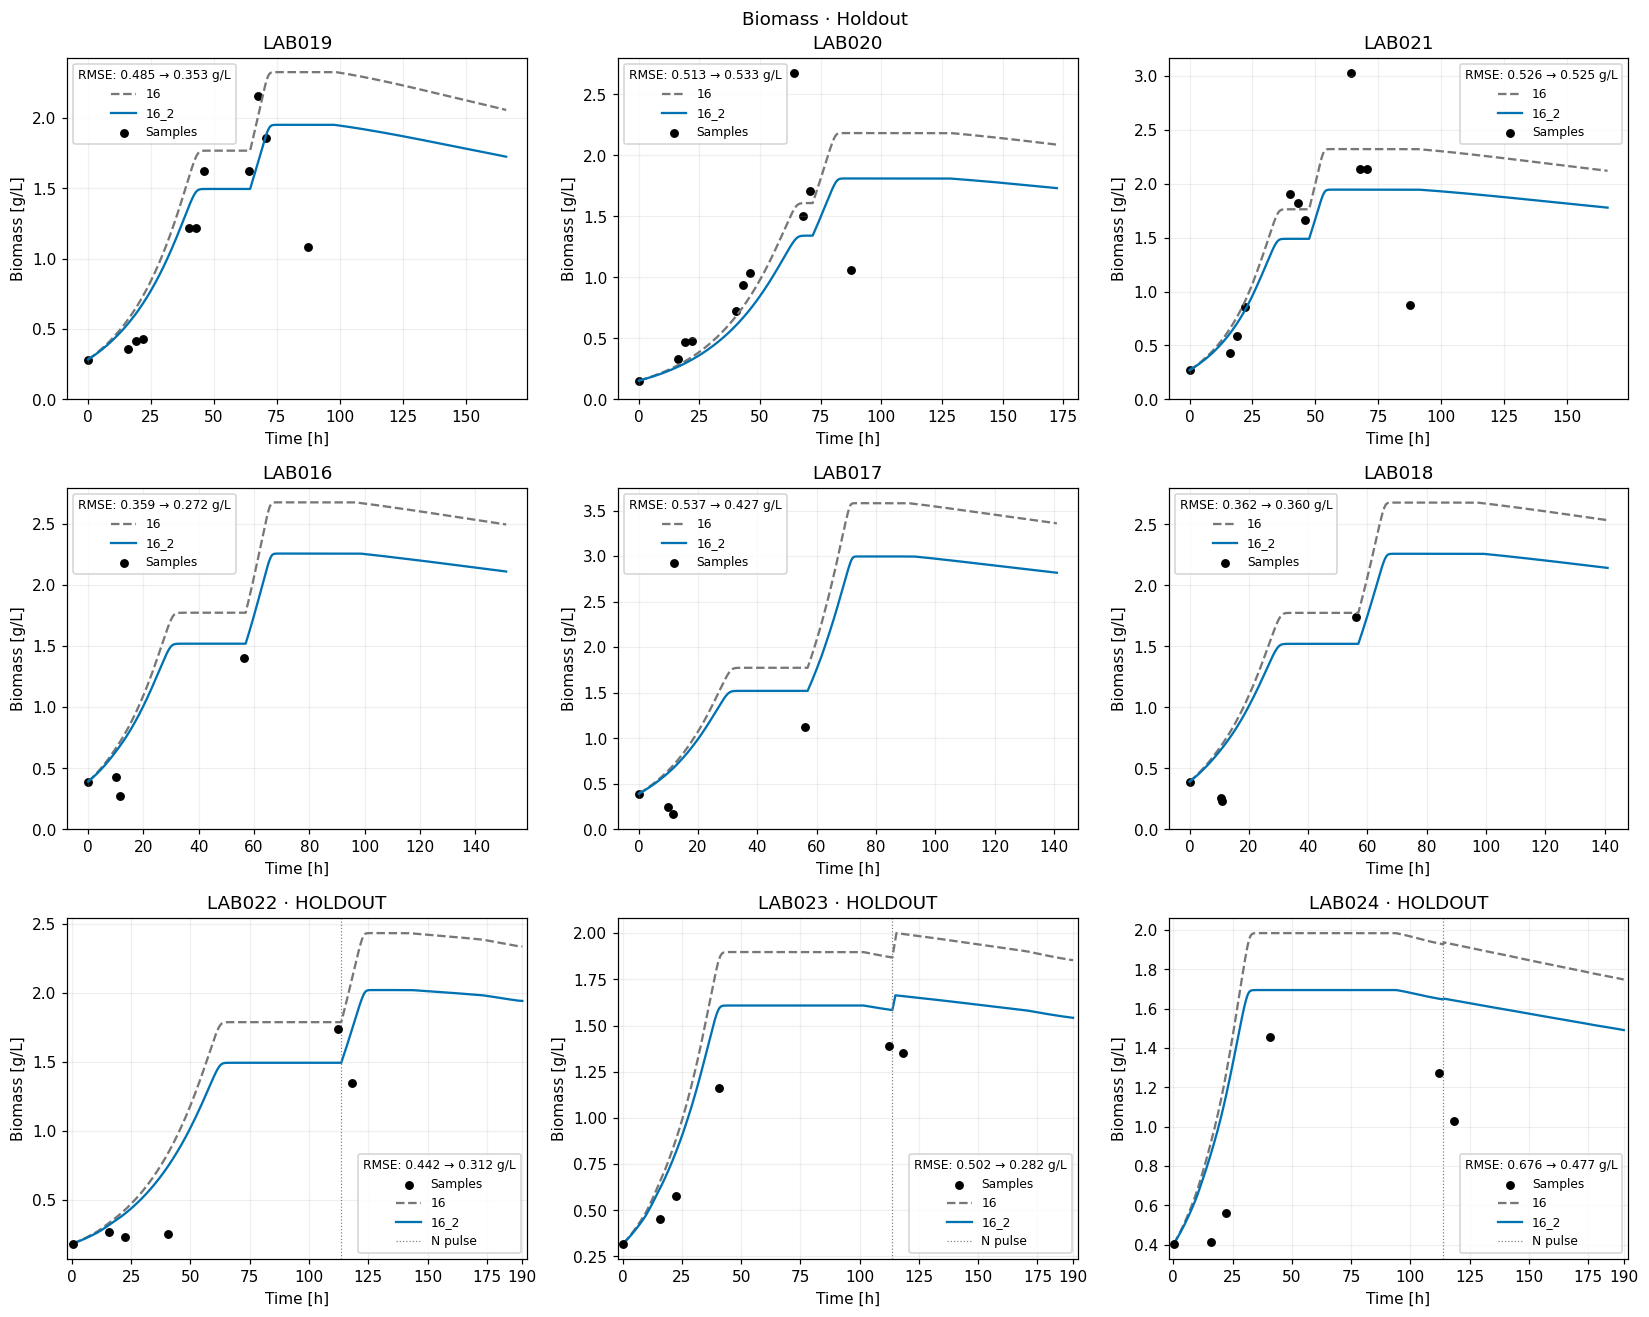

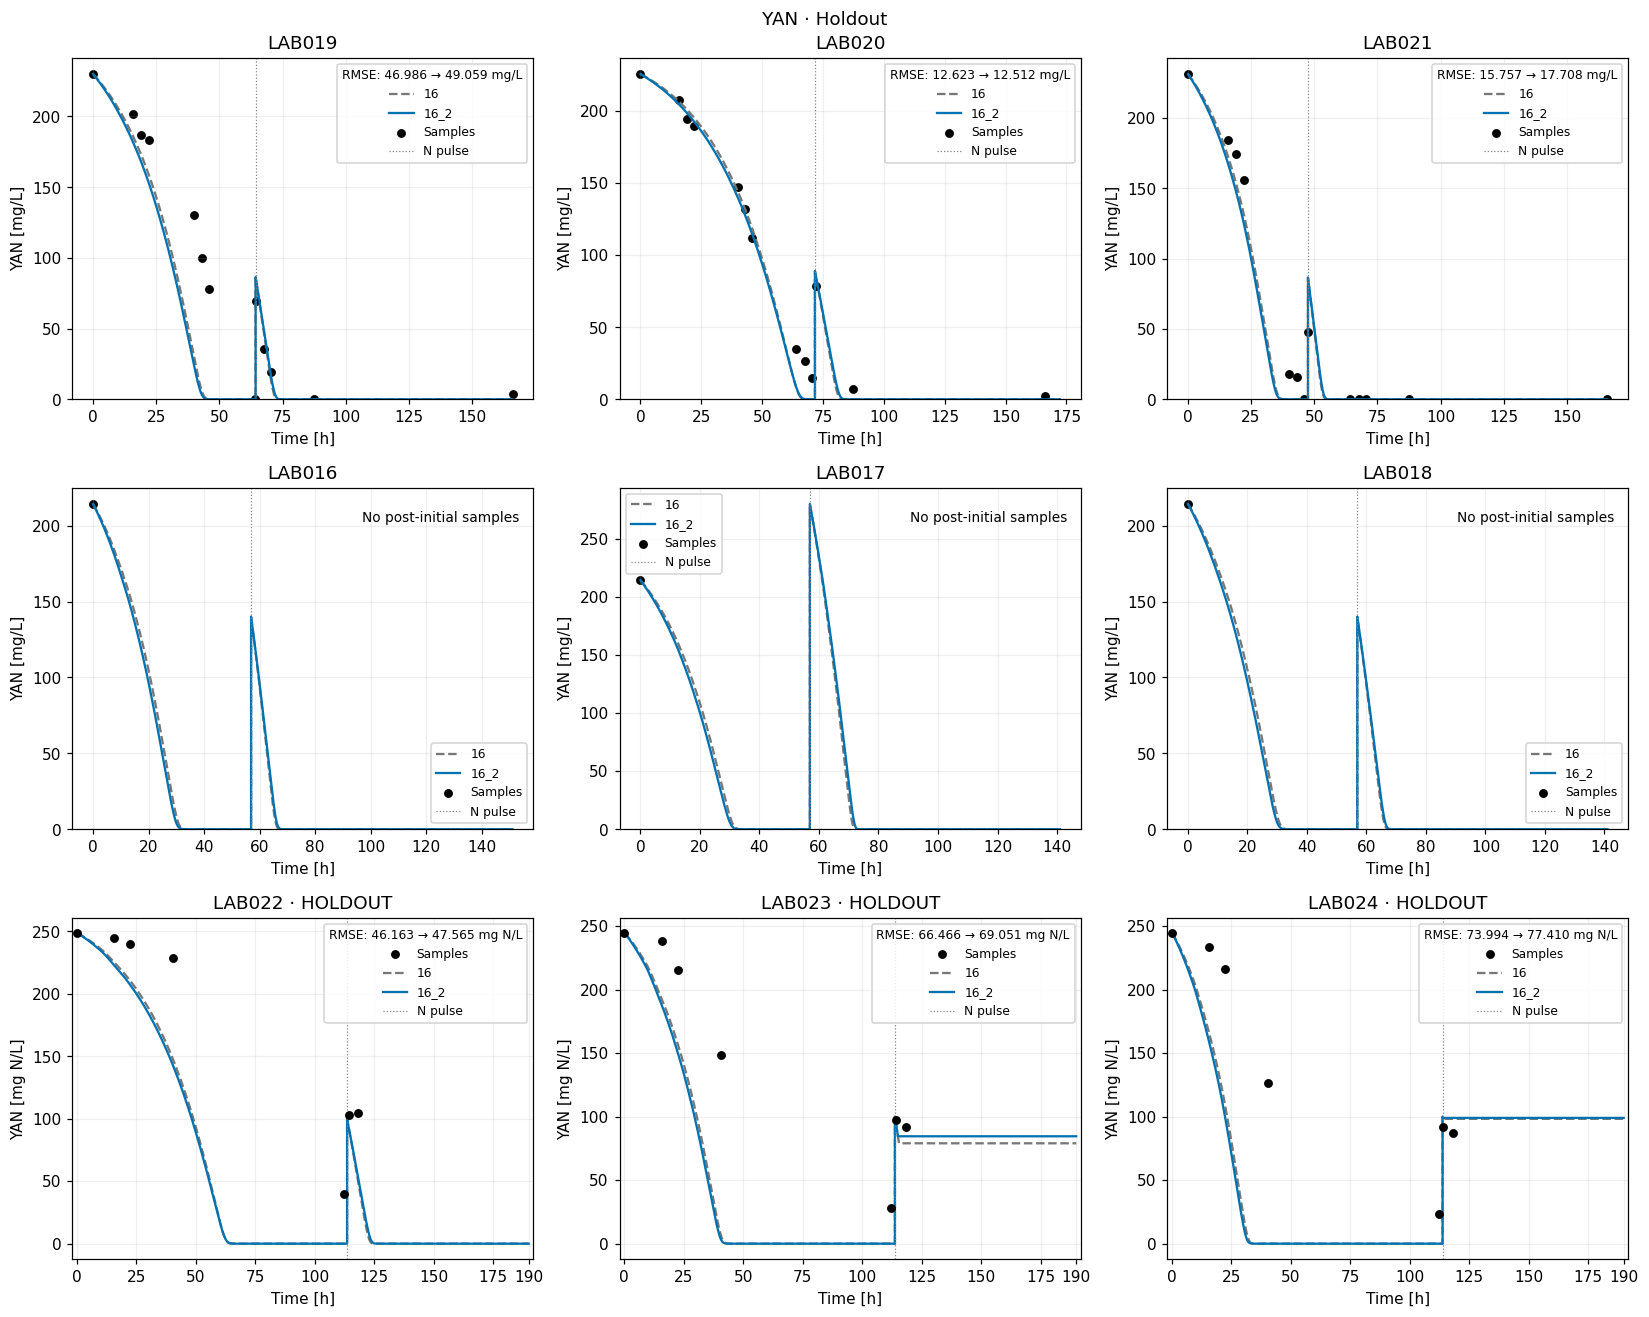

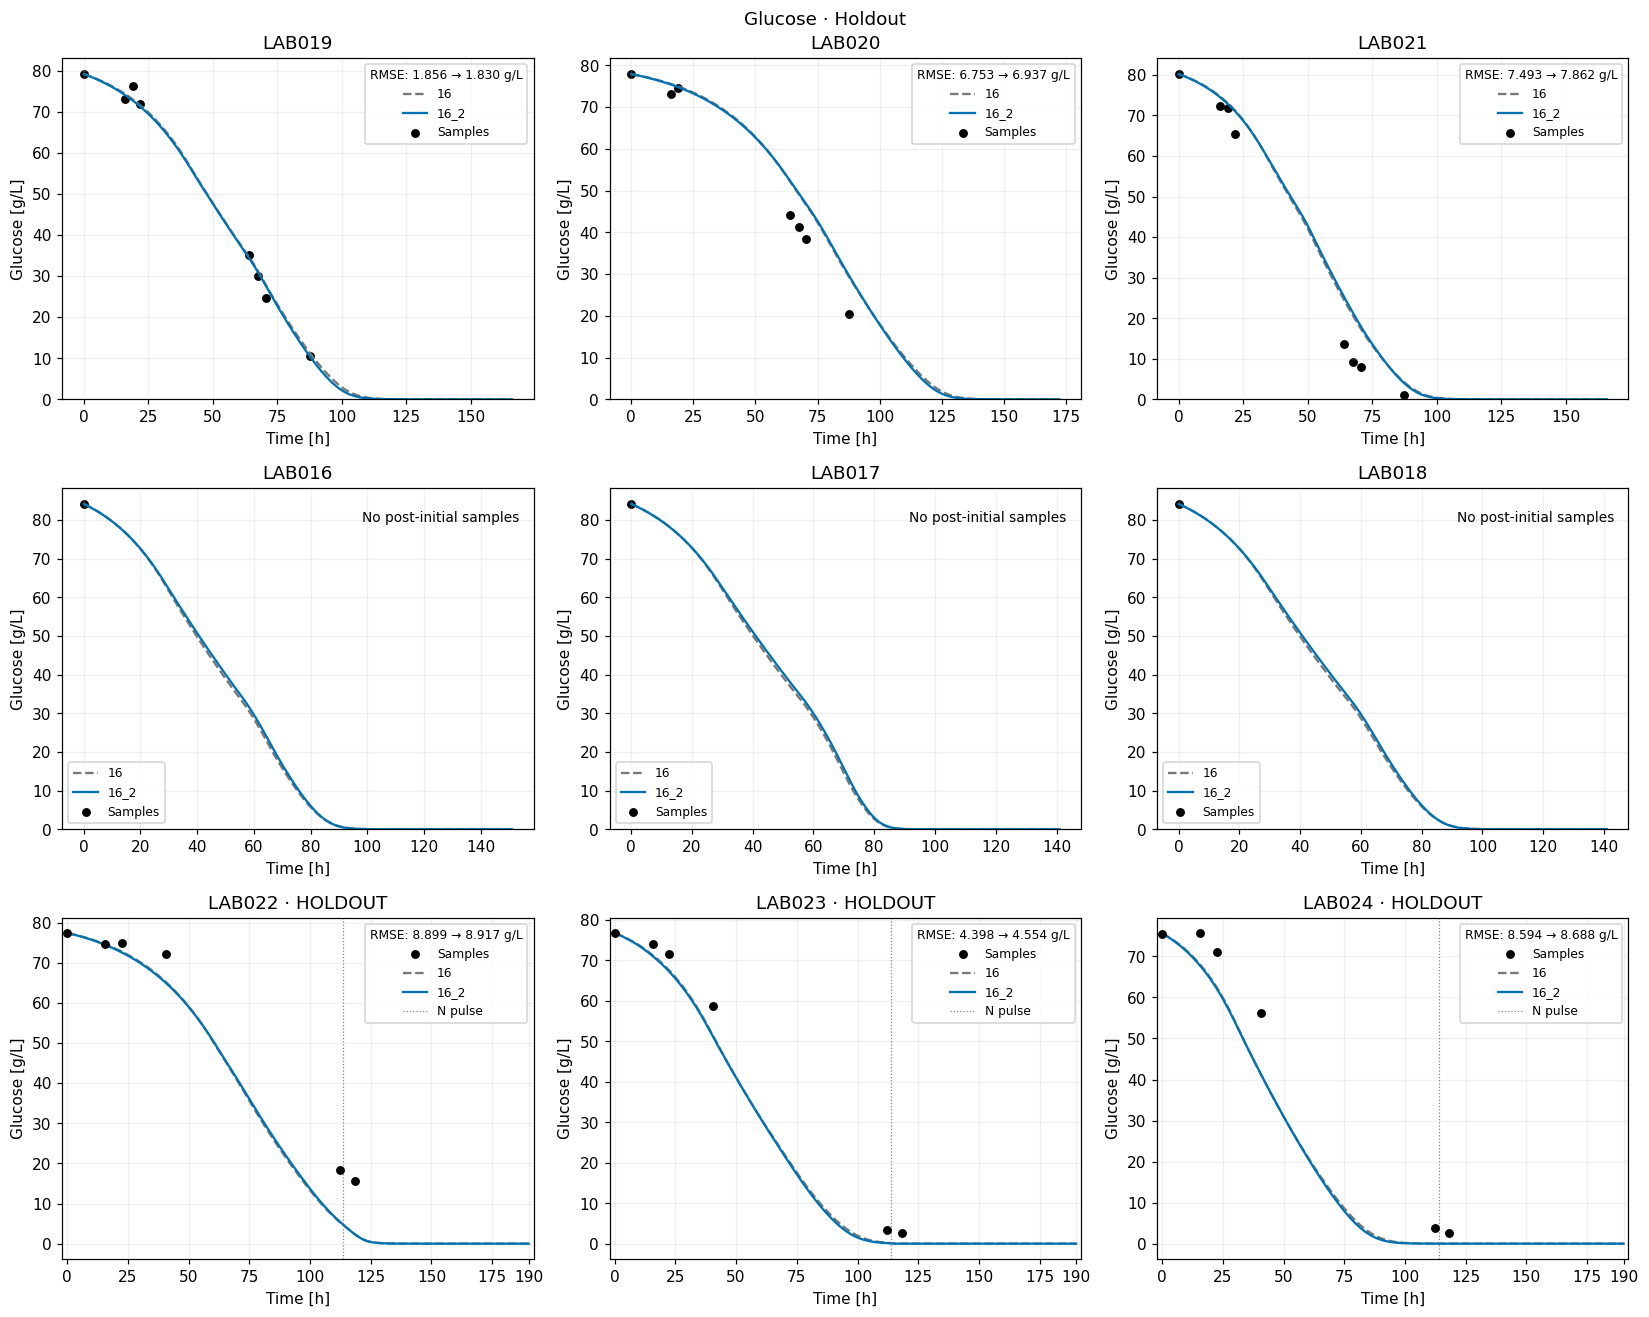

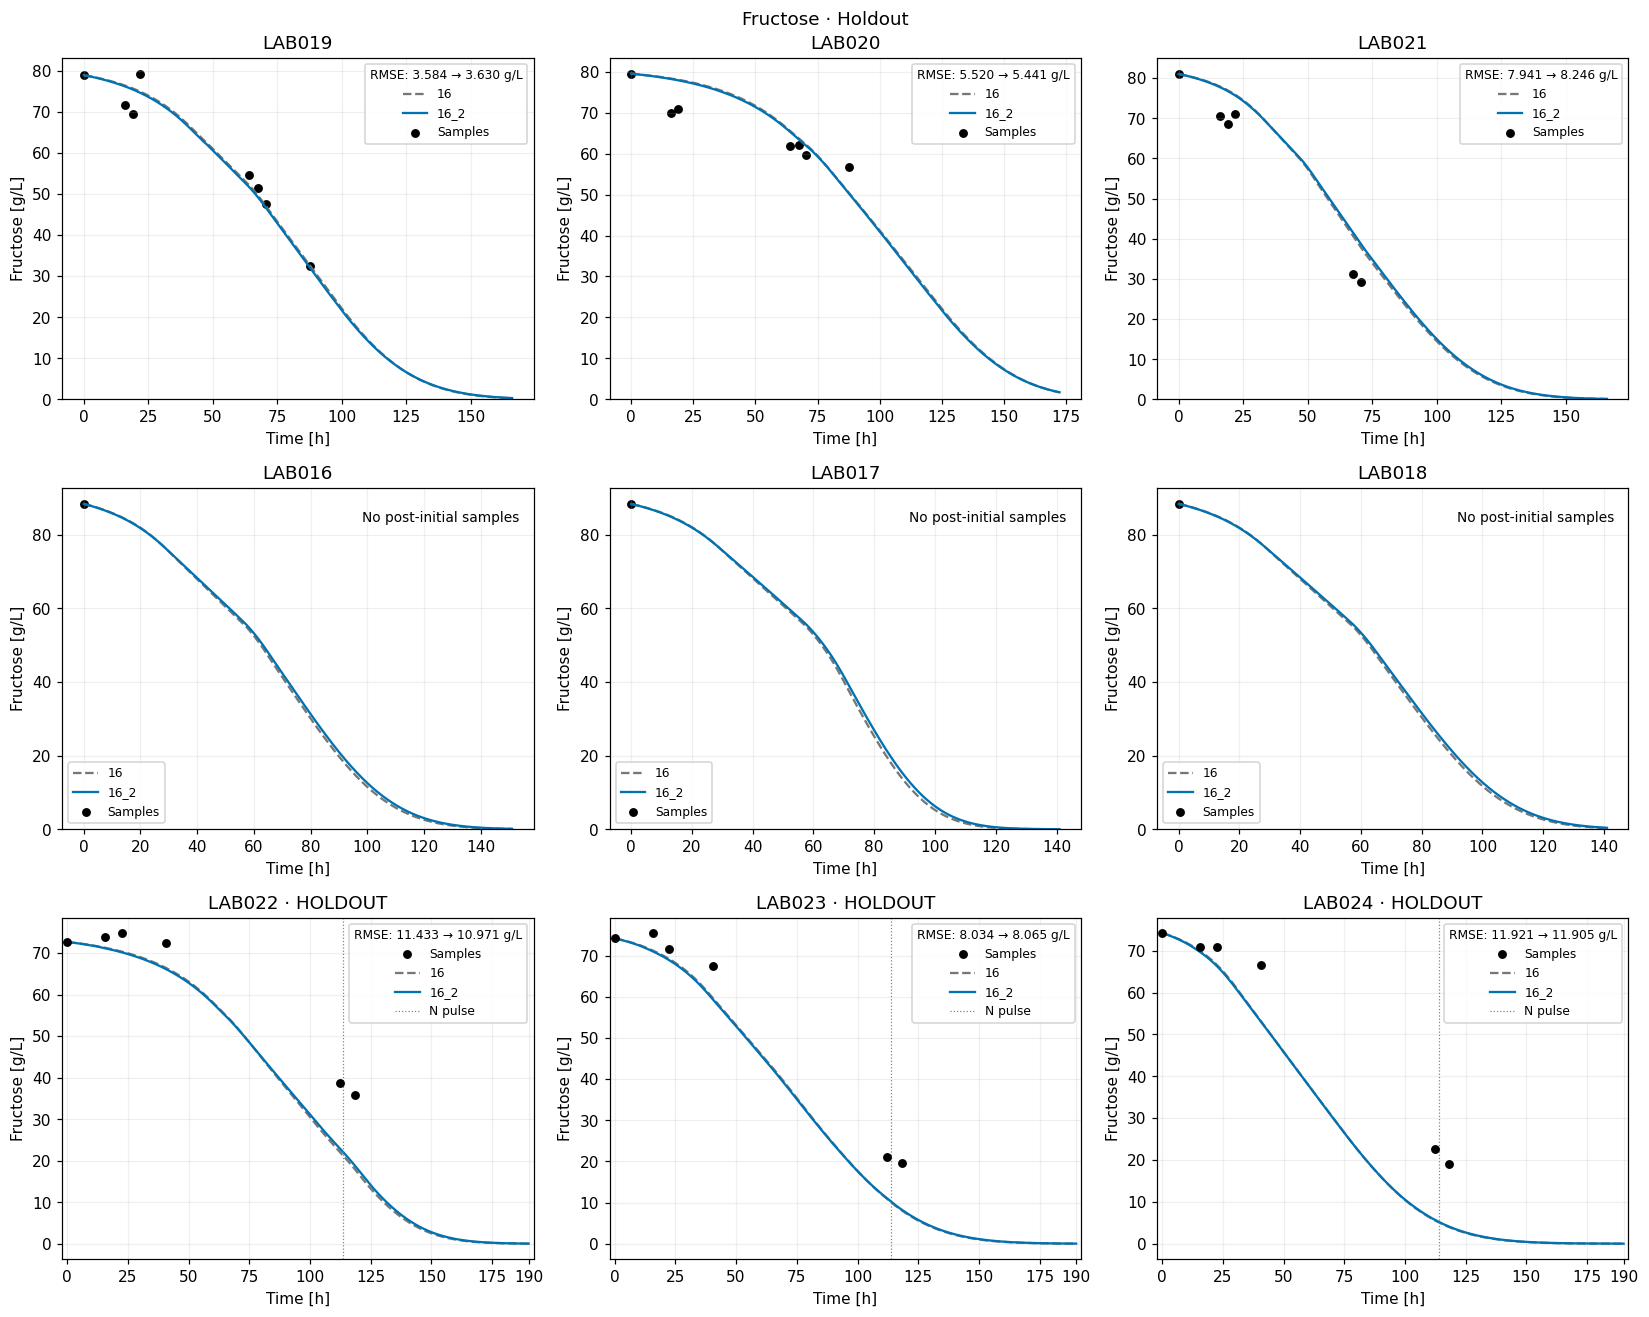

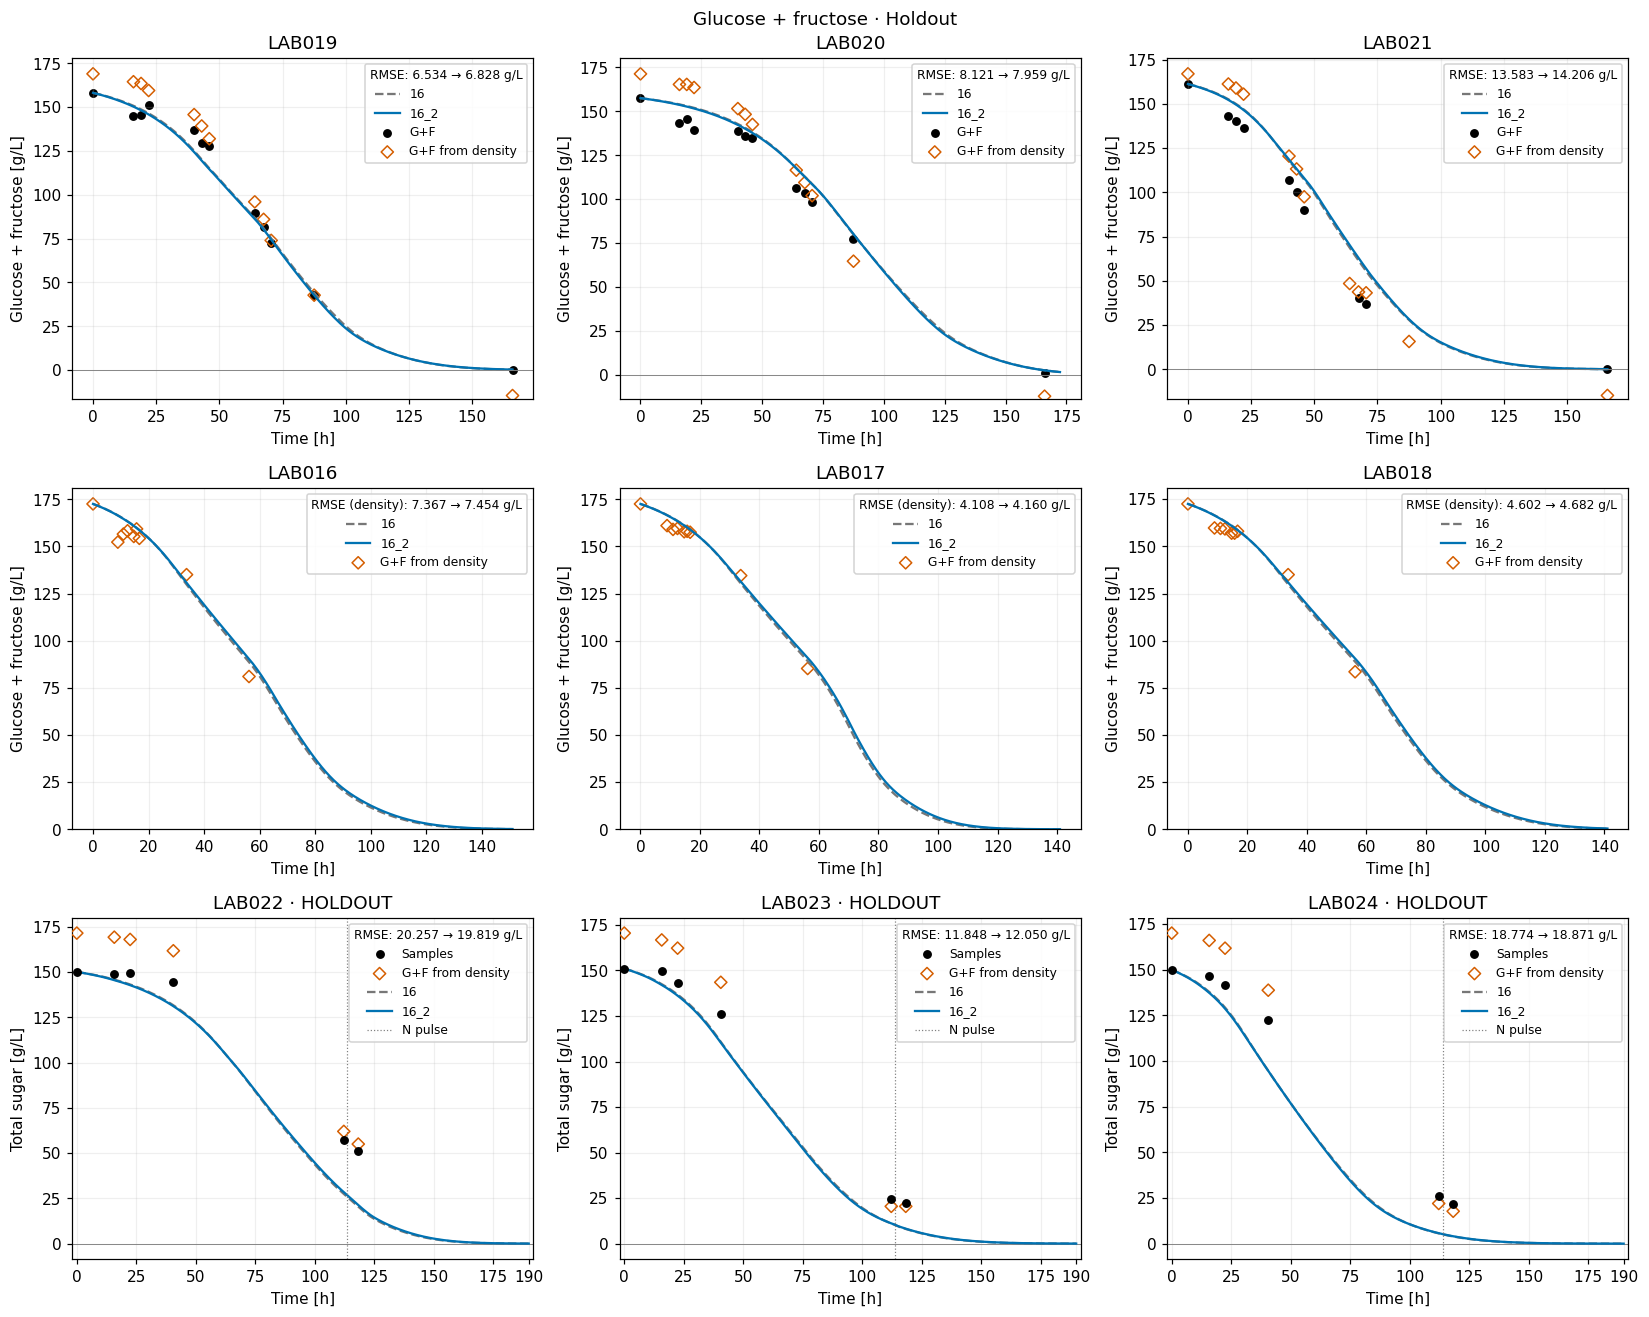

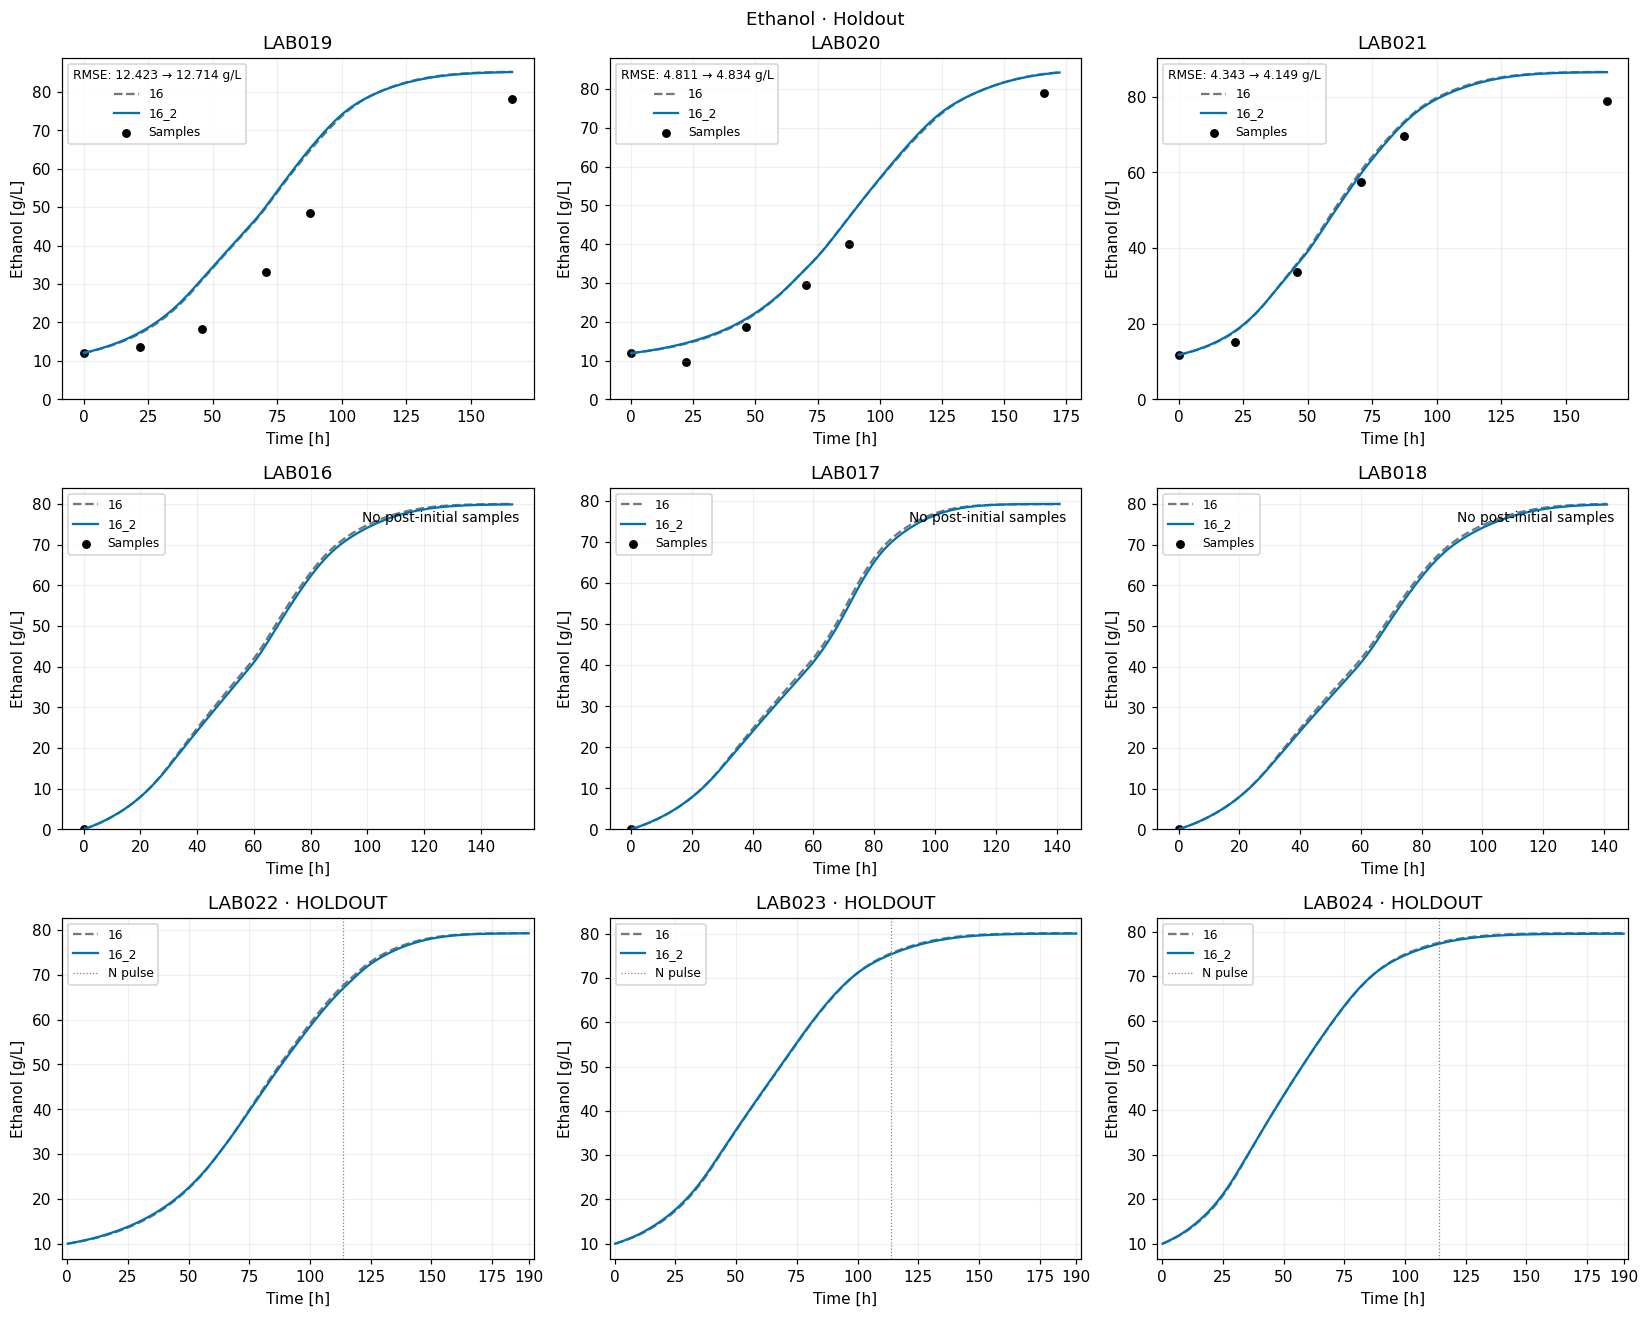

,LAB,variable,n,RMSE_16,RMSE_16_2
0,LAB019,X,10,0.484605,0.352880
1,LAB020,X,10,0.513404,0.533150
2,LAB021,X,10,0.526470,0.525256
3,LAB016,X,3,0.359155,0.271855
4,LAB017,X,3,0.536581,0.426742
5,LAB018,X,3,0.362133,0.360333
6,LAB019,N,12,46.985655,49.058839
7,LAB020,N,12,12.622841,12.511681
8,LAB021,N,12,15.757195,17.708376
9,LAB019,G,7,1.855855,1.829751


,n,RMSE_16,RMSE_16_2
LAB,,,
LAB019,166,0.1122,0.1165
LAB020,172,0.0744,0.0760
LAB021,166,0.1835,0.1916
LAB016,152,0.1357,0.1338
LAB017,141,0.1344,0.1349
LAB018,141,0.1227,0.1247


,n_mediciones
lab,
LAB016,9
LAB017,9
LAB018,9
LAB019,12
LAB020,12
LAB021,12


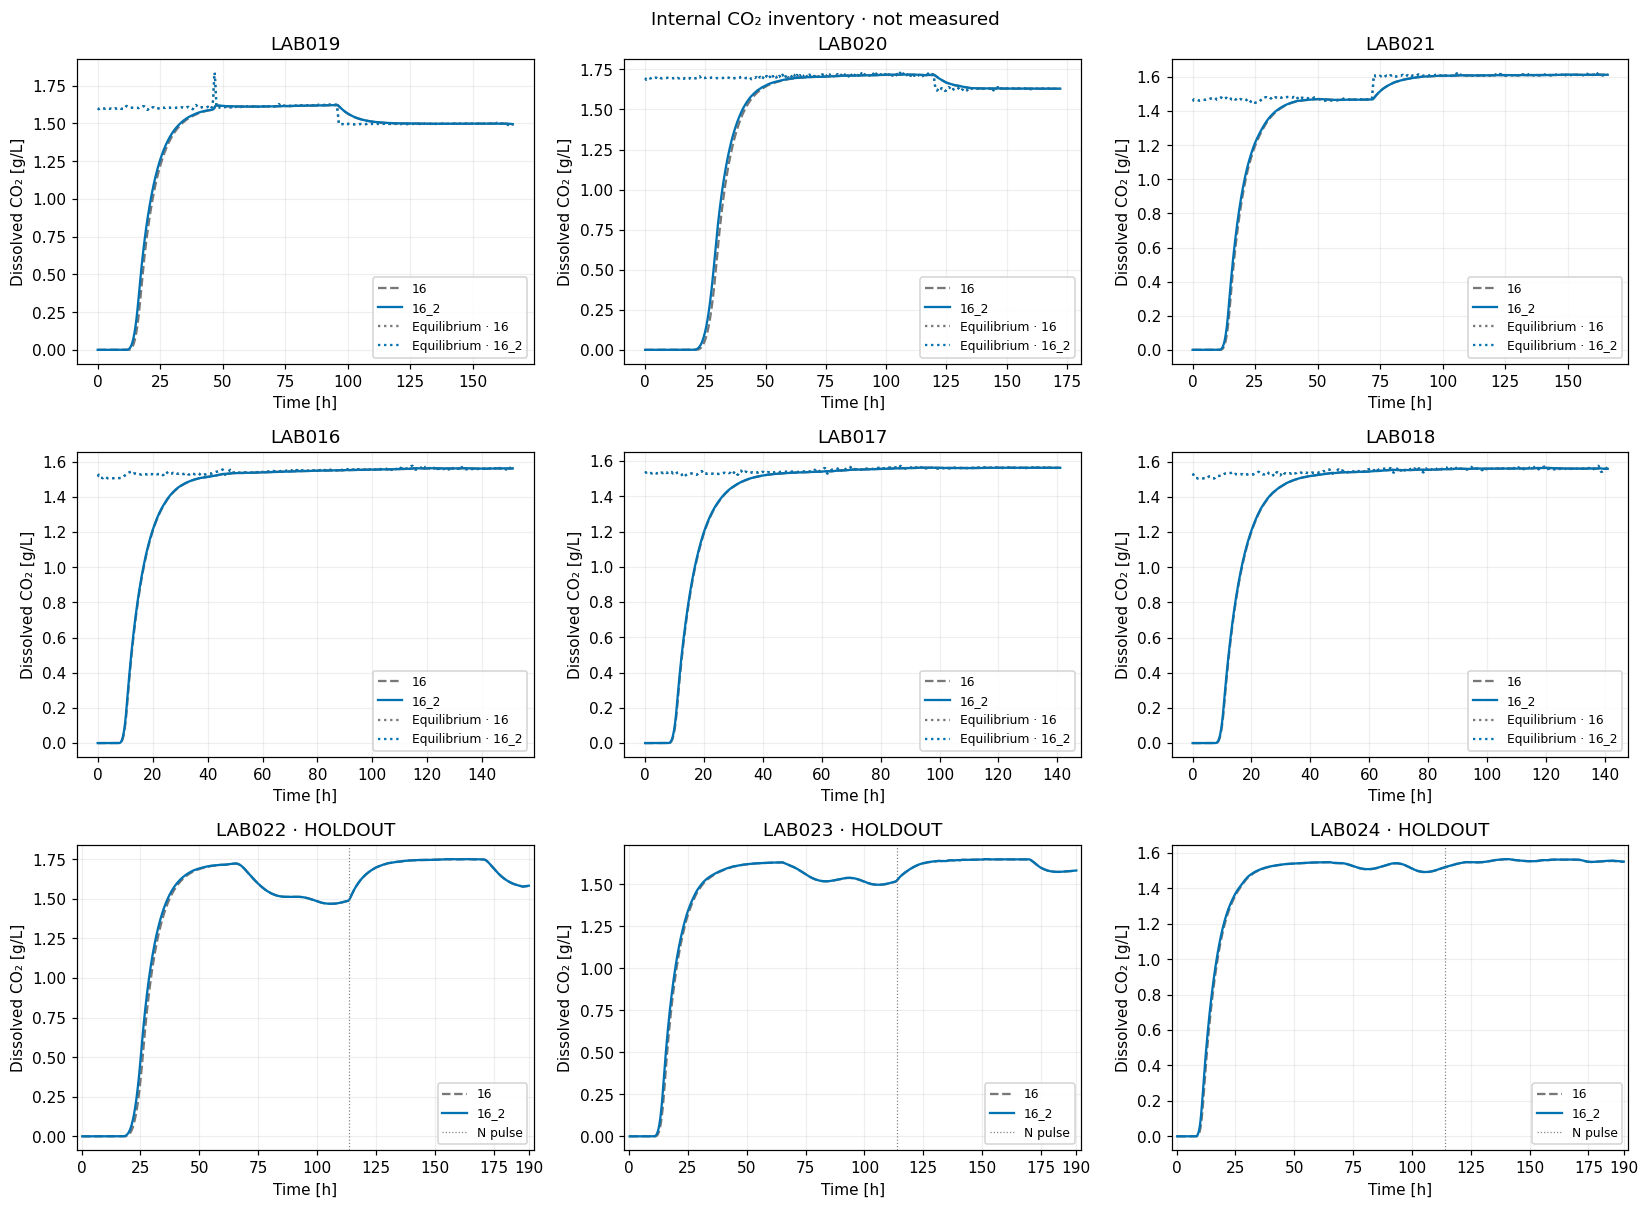

,,,n,RMSE 16,RMSE 16_2
LAB,Variable,Unit,,,
LAB022,CO₂ flow · 30-min mean,g/(L h),378,0.2136,0.2141
LAB023,CO₂ flow · 30-min mean,g/(L h),378,0.1494,0.1520
LAB024,CO₂ flow · 30-min mean,g/(L h),378,0.1755,0.1765
LAB022,Biomass,g/L,5,0.4417,0.3117
LAB023,Biomass,g/L,5,0.5019,0.2824
LAB024,Biomass,g/L,5,0.6760,0.4775
LAB022,YAN,mg N/L,6,46.1625,47.5650
LAB023,YAN,mg N/L,6,66.4661,69.0505
LAB024,YAN,mg N/L,6,73.9939,77.4098


In [11]:
def legend_inside(ax):
 handles,labels=ax.get_legend_handles_labels()
 unique=dict(zip(labels,handles))
 legend=ax.legend(unique.values(),unique.keys(),loc='best',fontsize=8,framealpha=.85,title=getattr(ax,'_rmse_text',None),title_fontsize=8)
 assert len(legend.get_texts())==len(unique)

panels = [
    ("X", "Biomass", "g/L", holdout_biomass, "X_g_L", 1.),
    ("N", "YAN", "mg N/L", holdout_chemistry, "YAN for plot", 1000.),
]
if not HOLDOUT_SINGLE:
    panels.extend([
        ("G", "Glucose", "g/L", holdout_chemistry, "GLUCOSE-320", 1.),
        ("F", "Fructose", "g/L", holdout_chemistry, "Fructose (derived)", 1.),
    ])
panels.extend([
    ("S" if HOLDOUT_SINGLE else "GF", "Total sugar", "g/L", holdout_chemistry, "GLU-FRU-320", 1.),
    ("E", "Ethanol", "g/L", None, None, 1.),
    ("Cd", "Dissolved CO₂", "g/L", None, None, 1.),
    ("CO2", "CO₂ flow · 30-min mean", "g/(L h)", None, None, 1.),
])
holdout_metrics = []
holdout_panels = {panel[0]: panel[1:] for panel in panels}


def draw_lab022_024_row(axes, state):
    title, unit, sample_frame, column, factor = holdout_panels[state]
    for ax, lab in zip(axes, holdout_labs):
        errors = np.array([])
        errors16 = np.array([])
        if state == "CO2":
            prediction = holdout_mean_gas[lab]
            prediction16 = holdout_mean_gas16[lab]
            observed = holdout_flow[lab]
            ax.plot(observed.index, observed, color="black", lw=1, label="Samples")
            errors = (prediction - observed).dropna().to_numpy()
            errors16 = (prediction16 - observed).dropna().to_numpy()
        elif state == "Cd":
            prediction = holdout_gas[lab]["Cd"]
            prediction16 = holdout_gas16[lab]["Cd"]
        else:
            prediction = holdout_plot[lab][state] * factor
            prediction16 = holdout_plot16[lab][state] * factor
            if sample_frame is not None:
                samples = sample_frame.loc[sample_frame["lab"].eq(lab)].dropna(subset=[column])
                ax.scatter(samples["hours"], samples[column], c="black", s=23, label="Samples", zorder=5)
                evaluation = samples.loc[samples["sample"].ne("01")]
                at_sample = holdout_kinetic[lab].loc[evaluation["hours"].to_numpy(), state].to_numpy()
                errors = at_sample * factor - evaluation[column].to_numpy()
                at_sample16 = holdout_kinetic16[lab].loc[evaluation["hours"].to_numpy(), state].to_numpy()
                errors16 = at_sample16 * factor - evaluation[column].to_numpy()
        if state == "GF":
            density = prepared["offline"]
            density = density.loc[density["lab"].eq(lab) &
                                  density["hours"].between(0, holdout_horizon)].dropna(subset=["Densidad_g_L"])
            inferred_sugar = 2.5 * (density["Densidad_g_L"] - 1000)
            ax.scatter(density["hours"], inferred_sugar, marker="D", facecolors="none",
                       edgecolors="#D55E00", s=32, label="G+F from density", zorder=4)
            ax.axhline(0, color="gray", lw=.6)
            assert len(density) > 0
        ax.plot(prediction16.index, prediction16, c="#777777", ls="--", lw=1.5, label="16")
        ax.plot(prediction.index, prediction, c="#0072B2", lw=1.5, label="16_2")
        ax.axvline(holdout_nutrition[lab], c="gray", ls=":", lw=.8, label="N pulse")
        legend_title = None
        if len(errors):
            rmse = np.sqrt(np.mean(errors**2))
            assert len(errors16) == len(errors)
            rmse16 = np.sqrt(np.mean(errors16**2))
            holdout_metrics.append({"LAB": lab, "Variable": title, "n": len(errors),
                                    "RMSE 16": rmse16, "RMSE 16_2": rmse, "Unit": unit})
            legend_title = f"RMSE: {rmse16:.3f} → {rmse:.3f} {unit}"
        ax.set(title=f"{lab} · HOLDOUT", xlabel="Time [h]", xlim=(-2, holdout_horizon + 2),
               xticks=[0, 25, 50, 75, 100, 125, 150, 175, 190])
        ax.grid(alpha=.2)
        ax.set_ylabel(f"{title.split(chr(183))[0].strip()} [{unit}]")
        ax._rmse_text = legend_title


gas_comparison = []
fig,axs=plt.subplots(3,3,figsize=(15,12))
for ax,lab in zip(axs[:2].flat,LABS):
 f=curves[lab];m=f.index<=v.horizons[lab];o=obs[lab]
 f16=curves16[lab];m16=f16.index<=v.horizons[lab]
 rmse16=np.sqrt(np.mean((np.interp(o.time_h,f16.index,f16.qpred)-o.co2_raw_g_l_h)**2))
 rmse2=metrics.loc[metrics.LAB.eq(lab),'RMSE'].item()
 gas_comparison.append(dict(LAB=lab,n=len(o),RMSE_16=rmse16,RMSE_16_2=rmse2))
 ax._rmse_text=f"RMSE: {rmse16:.3f} → {rmse2:.3f} g/(L h)"
 ax.plot(f16.index[m16],f16.qpred[m16],label='16',c='#777777',ls='--')
 ax.plot(f.index[m],f.qpred[m],label='16_2',c='#0072B2')
 ax.plot(o.time_h,o.co2_raw_g_l_h,c='black',lw=1,label='Samples')
 ax.set(title=lab+(' · calibration' if lab in TRAIN else ' · HOLDOUT'),xlabel='Time [h]',ylabel='CO₂ [g/(L·h)]',ylim=(0,None));ax.grid(alpha=.2)
draw_lab022_024_row(axs[-1], 'CO2')
fig.suptitle('CO₂ · calibration LAB019–021 and holdout LAB016–018 / LAB022–024',y=.99);fig.tight_layout(pad=.7,h_pad=1.2,w_pad=.9);[legend_inside(ax) for ax in axs.flat];assert not fig.legends;plt.show()
chemmetrics=[]
for s,title,scale in [('X','Biomass',1),('N','YAN',1000),('G','Glucose',1),('F','Fructose',1),('GF','Glucose + fructose',1),('E','Ethanol',1)]:
 fig,axs=plt.subplots(3,3,figsize=(15,12));items={}
 for ax,lab in zip(axs[:2].flat,LABS):
  f16=with_jumps(cores16[lab]);m16=f16.index<=v.horizons[lab]
  f=with_jumps(cores[lab]);m=f.index<=v.horizons[lab]
  ax.plot(f16.index[m16],f16[s][m16]*scale,c='#777777',ls='--',label='16')
  ax.plot(f.index[m],f[s][m]*scale,c='#0072B2',label='16_2')
  if lab in TRAIN:
   z=chemical_observations(v.chem,lab,s);tt=z.t_h.to_numpy();yy=z[CHEMICAL_COLUMNS[s]].to_numpy();label='G+F' if s=='GF' else 'Samples'
  elif s=='X':
   z=v.biomass.loc[v.biomass.lab.eq(lab)].dropna(subset=['t_h','X_viable_g_l']);tt=z.t_h.to_numpy();yy=z.X_viable_g_l.to_numpy();label='Samples'
  elif s=='GF':
   z=v.density.loc[v.density.lab.eq(lab)].dropna(subset=['t_h','density_g_l']);tt=z.t_h.to_numpy();yy=2.5*(z.density_g_l.to_numpy()-1000);label='G+F from density'
  else:tt=np.array([]);yy=np.array([]);label='No data available'
  if len(tt):
   if s=='GF' and lab not in TRAIN:ax.scatter(tt,yy*scale,marker='D',facecolors='none',edgecolors='#D55E00',s=32,label=label)
   else:
    noninitial=~np.isclose(tt,0.)
    ax.scatter(tt[noninitial],yy[noninitial]*scale,c='black',s=23,label=label)
  if s!='GF' or lab in TRAIN:
   initial_value=(batches[lab].initials['G']+batches[lab].initials['F']) if s=='GF' else batches[lab].initials[s]
   initial_point=ax.scatter([0.],[initial_value*scale],c='black',s=23,label='G+F' if s=='GF' else 'Samples')
   assert np.allclose(initial_point.get_offsets(),[[0.,initial_value*scale]])
  if not len(tt):ax.text(.97,.9,'No post-initial samples',ha='right',transform=ax.transAxes,fontsize=9)
  score=(tt>0)&(tt<=v.horizons[lab])
  if score.any():
   e=(np.interp(tt[score],f.index,f[s])-yy[score])*scale
   e16=(np.interp(tt[score],f16.index,f16[s])-yy[score])*scale
   rmse16,rmse2=(np.sqrt(np.mean(error**2)) for error in (e16,e))
   chemmetrics.append(dict(LAB=lab,variable=s,n=score.sum(),RMSE_16=rmse16,RMSE_16_2=rmse2))
   reference='RMSE (density)' if s=='GF' and lab not in TRAIN else 'RMSE'
   ax._rmse_text=f"{reference}: {rmse16:.3f} → {rmse2:.3f} {'mg/L' if s=='N' else 'g/L'}"
  if s=='GF':
   zd=v.density.loc[v.density.lab.eq(lab)].dropna(subset=['t_h','density_g_l'])
   if lab in TRAIN:
    ax.scatter(zd.t_h,2.5*(zd.density_g_l-1000),marker='D',facecolors='none',edgecolors='#D55E00',s=32,label='G+F from density')
  if s=='N':
   for t,d in batches[lab].pulses['N']:ax.axvline(t,c='gray',ls=':',lw=.8,label='N pulse')
  ax.set(title=lab,xlabel='Time [h]',ylabel=title+(' [mg/L]' if s=='N' else ' [g/L]'),ylim=(0,None));ax.grid(alpha=.2)
  if s=='GF':
   ax.set_ylim(bottom=min(0.,float((2.5*(zd.density_g_l-1000)).min())*1.15));ax.axhline(0,c='gray',lw=.6)
  for h,l in zip(*ax.get_legend_handles_labels()):items[l]=h
 expected={'16','16_2','G+F','G+F from density'} if s=='GF' else {'16','16_2','Samples'}|({'N pulse'} if s=='N' else set());assert set(items)==expected
 draw_lab022_024_row(axs[-1],s)
 fig.suptitle(title+' · Holdout',y=.99);fig.tight_layout(pad=.7,h_pad=1.2,w_pad=.9);[legend_inside(ax) for ax in axs.flat];assert not fig.legends;plt.show()
display(pd.DataFrame(chemmetrics))
display(pd.DataFrame(gas_comparison).set_index('LAB').round(4))
display(v.density.dropna(subset=['t_h','density_g_l']).groupby('lab').agg(n_mediciones=('density_g_l','size')))
print('G+F from density = 2.5*(densidad g/L - 1000); comparación gráfica, no usada en el ajuste; se conservan valores negativos de la conversión.')
fig,axs=plt.subplots(3,3,figsize=(15,11))
for ax,lab in zip(axs[:2].flat,LABS):
 f16=curves16[lab];m16=f16.index<=v.horizons[lab]
 f=curves[lab];m=f.index<=v.horizons[lab]
 ax.plot(f16.index[m16],f16.Cd[m16],c='#777777',ls='--',label='16')
 ax.plot(f.index[m],f.Cd[m],c='#0072B2',label='16_2')
 ax.plot(f16.index[m16],f16.Csat[m16],c='#777777',ls=':',label='Equilibrium · 16')
 ax.plot(f.index[m],f.Csat[m],c='#0072B2',ls=':',label='Equilibrium · 16_2')
 ax.set(title=lab,xlabel='Time [h]',ylabel='Dissolved CO₂ [g/L]');ax.grid(alpha=.2)
draw_lab022_024_row(axs[-1], 'Cd')
fig.suptitle('Internal CO₂ inventory · not measured',y=.99);fig.tight_layout(pad=.7,h_pad=1.2,w_pad=.9);[legend_inside(ax) for ax in axs.flat];assert not fig.legends;plt.show()


display(pd.DataFrame(holdout_metrics).set_index(["LAB", "Variable", "Unit"]).round(4))

In [12]:
display(pd.DataFrame([dict(LAB=lab,t_h=j['t'],dosis_g_L=j['dose'],N_pre_g_L=j['before'][1],N_post_g_L=j['after'][1]) for lab,f in {**traincurves,**cores}.items() for j in f.attrs['pulse_jumps']]))
display(pd.DataFrame([dict(LAB=lab,**f.attrs['minimum_integrated_states']) for lab,f in cores.items()]))
masschecks=[]
for lab in LABS:
 f=curves[lab];t=f.index.to_numpy();V=volumes[lab](t);dt=np.diff(t);q=f.qprod.to_numpy();cd=f.Cd.to_numpy();out=f.qgas.to_numpy()
 produced=np.sum(V[:-1]*dt*(q[:-1]+q[1:])/2);emitted=np.sum(V[:-1]*dt*out[1:]);removed=np.sum((V[:-1]-V[1:])*cd[1:]);err=V[-1]*cd[-1]-V[0]*cd[0]-produced+emitted+removed
 assert abs(err)<1e-8
 masschecks.append(dict(LAB=lab,produccion_g=produced,gas_g=emitted,retirado_disuelto_g=removed,final_disuelto_g=V[-1]*cd[-1],error_g=err))
display(pd.DataFrame(masschecks))


,LAB,t_h,dosis_g_L,N_pre_g_L,N_post_g_L
0,LAB004,68.500000,0.080000,-2.209800e-12,0.080000
1,LAB005,68.500000,0.080000,-6.931251e-12,0.080000
2,LAB006,100.000000,0.080000,-5.589519e-13,0.080000
3,LAB007,65.500000,0.080000,4.490529e-19,0.080000
4,LAB008,65.500000,0.080000,-4.619538e-12,0.080000
5,LAB009,41.846154,0.080000,5.052137e-11,0.080000
6,LAB019,64.333333,0.086486,5.666843e-17,0.086486
7,LAB020,71.666667,0.088889,6.212707e-07,0.088890
8,LAB021,47.500000,0.086486,2.908390e-12,0.086486
9,LAB016,56.935556,0.140000,-3.219756e-23,0.140000


,LAB,X,N,G,F,E
0,LAB019,0.284126,-1.329761e-11,2.874643e-09,0.067265,12.088309
1,LAB020,0.153783,-1.322518e-64,5.326023e-07,0.744603,11.924174
2,LAB021,0.271175,-4.700851e-13,4.194637e-11,0.021014,11.773017
3,LAB016,0.391576,-7.365135e-15,3.165590e-09,0.123999,0.020132
4,LAB017,0.391529,-3.195182e-10,2.909769e-13,0.004219,0.019971
5,LAB018,0.391531,-3.678987e-66,3.204039e-09,0.126669,0.019978


,LAB,produccion_g,gas_g,retirado_disuelto_g,final_disuelto_g,error_g
0,LAB019,121.517183,118.597055,0.369194,2.550934,5.662137e-15
1,LAB020,118.607278,115.503236,0.333345,2.770697,-1.615375e-14
2,LAB021,125.302383,122.200831,0.360859,2.740693,-4.773959e-15
3,LAB016,146.237942,143.115624,0.000000,3.122318,-2.842171e-14
4,LAB017,145.143372,142.019619,0.000000,3.123752,0.000000e+00
5,LAB018,146.248228,143.125102,0.000000,3.123126,0.000000e+00
